# 2026-10-20 NSF corrected Halpha flux and the HOLMES photon budget

1. EW(Halpha) versus **all-emission dust-corrected Halpha flux**, for NSF only.
2. Projected distance to the nearest selected SF spaxel with **EW(Halpha)>20 Angstrom** versus corrected Halpha flux.
3. Equation 33 HOLMES prediction versus corrected Halpha flux; counts, fractions and distributions of the predicted/observed ratio.
4. Each admitted galaxy/product's NSF map of $\Delta=\log_{10}F_{\alpha,\mathrm{HOLMES}}-\log_{10}F_{\alpha,\mathrm{corr}}$, with a common zero-centred `coolwarm` scale.

Derived from `20261017_check_NSF_SII_ratio_EW_SF_proximity_sigma_by_stage.ipynb`.
The source is unchanged. This notebook reads live products and does not write FITS products.

## Material Passport and sample
Exploratory observational analysis; local MAUVE products; galaxy/product is the independent cluster (`NGC4567_8` remains one product). Inherited inclination<80 deg, nGIST mask=0, finite mass/radius support, Balmer detections, and stellar SNR_POSTFIT>25. **NSF means Balmer-detected pixels failing the original SF selection**, not exclusively BPT LI(N)ERs: SF requires the inherited finite dual-BPT HII SFR, EW>6 Angstrom and intrinsic Halpha sigma<45 km/s. No TNSF, sulfur detection cut, or high-mass restriction. Paired finite support is reported separately for each diagnostic.

Point clouds, pooled-spaxel fractions and equal-galaxy summaries are descriptive. Spaxels share PSF and fitting bins; their counts are not independent sample sizes. No significance tests or independent-spaxel confidence intervals are assigned. The map pages include every product passing the inherited QC, and the QC table lists excluded candidates.

Dated copy of the 20261019 notebook. Cells immediately after the original cell 20 add local stellar-surface-density, radius, and joint-bin PDFs.


In [1]:
from __future__ import annotations

import math
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
DATA_ROOT = PROJECT_ROOT / "v3tk_v7.6.8"
CATALOG_PATH = PROJECT_ROOT / "mauve_master_wiki_newclass.fits"
GEOMETRY_PATH = PROJECT_ROOT / "MAUVE_effective_radii.csv"

MASS_FILE_PATTERN = "{galid}_spatial_binning_maps_further.fits"
SFR_FILE_PATTERNS = (
    "{galid}_gas_bin_maps_further.fits",
    "{galid}_gas_BIN_maps_further.fits",
)
EW_FILE_PATTERNS = (
    "{galid}_proxy_EW_maps_further.fits",
    "{galid}_proxy_EW_maps.fits",
)
MASK_FILE_PATTERN = "{galid}_mask.fits"
SFH_FILE_PATTERN = "{galid}_sfh_maps.fits"

MASS_HDU = "LOGMASS_SURFACE_DENSITY"
BIN_HDU_MASS = "BINID"
BIN_HDU_GAS = "BIN_ID"
SFR_HDU = "LOGSFR_SURFACE_DENSITY_HII"
# All-spaxel ordinate only; SFR_HDU remains the original SF-selection map.
ALL_SFR_HDU = "LOGSFR_SURFACE_DENSITY"
EW_HDU = "PROXY_EWHA"
HALPHA_SIGMA_OBS_HDU = "HA6562_SIGMA"
HALPHA_SIGMA_CORR_HDU = "HA6562_SIGMA_CORR"
MASK_TABLE_HDU = "MASKFILE"
MASK_COLUMN = "MASK"
SFH_SNR_POSTFIT_HDU = "SNR_POSTFIT"

EW_HA_MIN = 6.0
# Distance references only; the inherited SF/NSF classification stays at EW > 6.
SF_REFERENCE_EW_HA_MIN = 20.0
HALPHA_SIGMA_MAX = 45.0
SFH_SNR_POSTFIT_MIN = 25.0
I_MAX_PRIMARY = 80.0
MIN_VALID_PIXELS_PER_BIN = 50
MIN_SF_PIXELS_PER_BIN = 20
WCS_TOLERANCE_ARCSEC = 0.05

SIGMA_BIN_WIDTH = 0.25
RADIUS_BIN_WIDTH = 0.25
FIXED_RELIABLE_RANGES = {"log_sigma_star": (7.0, 9.5), "radius_re": (0.0, 2.5)}
MASS_CONTOUR_LEVEL = 7.5

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.grid": False,
})


BALMER_LINES = ("HB4861", "HA6562")
REASON_LABELS = (
    "BPT: stable non-HII", "BPT: weak/ambiguous/unavailable", "HII SFR unavailable",
    "EW unavailable", "EW <= 6", "Dispersion unavailable", "Dispersion >= 45",
)


from scipy.spatial import cKDTree
import astropy.units as u
import hashlib
import json

STAGE_ORDER = ('pre-peak', 'close-to-peak', 'post-peak')
PANEL_ORDER = STAGE_ORDER + ('all stages',)
STAGE_LABELS = {'pre-peak': 'Pre-peak', 'close-to-peak': 'Close-to-peak',
                'post-peak': 'Post-peak', 'all stages': 'All stages'}
STAGE_COLORS = {'pre-peak': '#2166ac', 'close-to-peak': '#1a9850', 'post-peak': '#d73027'}

Q_HOLMES = 7e40                 # ionizing photons / s / Msun current old mass
EPSILON_ALPHA = 1.3721e-12      # erg per absorbed ionizing photon, Eq. 33
MPC_CM = u.Mpc.to(u.cm)
MASS_DISTANCE_MPC = 16.5        # Mass.py photometric mass normalization
HOLMES_ABSORBED_FRACTION = 1.0  # full local absorption; budget assumption, not fitted
ASSET_DIR = PROJECT_ROOT / '20261020_NSF_Halpha_HOLMES_assets'
SAVE_OUTPUTS = True
SAVE_SPAXEL_TABLE = False  # Optional large export; summary tables are always saved.
if SAVE_OUTPUTS:
    ASSET_DIR.mkdir(exist_ok=True)
MAPS_PER_PAGE = 9
SOURCE_SHA256 = 'bda6338eb76ee5bdb8cf026ddda606585ef48f26dda7a687d2678177548058a9'

GALAXY_COLORS = {}
for line in (PROJECT_ROOT / 'MAUVE_galaxy_colors.dat').read_text().splitlines():
    if line.strip() and not line.lstrip().startswith('#'):
        fields = line.split()
        GALAXY_COLORS[fields[1]] = fields[3]

def finish_figure(fig, name):
    if SAVE_OUTPUTS:
        fig.savefig(ASSET_DIR / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Scope: NSF only, all stellar densities; corrected Halpha flux in cgs per spaxel')
print('HOLMES: Sigma_old approximately Sigma_star; full local absorption')
print(f'Selection: inclination < {I_MAX_PRIMARY:g} deg; SNR_POSTFIT > {SFH_SNR_POSTFIT_MIN:g}')

Scope: NSF only, all stellar densities; corrected Halpha flux in cgs per spaxel
HOLMES: Sigma_old approximately Sigma_star; full local absorption
Selection: inclination < 80 deg; SNR_POSTFIT > 25


## Live discovery and inherited NSF classification
The following self-contained helpers preserve the source classification and geometry. Missing files, inconsistent shapes or WCS failures appear in `SAMPLE_QC`; they are not treated as empty galaxies.

In [2]:
def normalise_stage_label(value) -> str:
    mapping = {
        1: "pre-peak", 1.0: "pre-peak", "1": "pre-peak",
        2: "close-to-peak", 2.0: "close-to-peak", "2": "close-to-peak",
        3: "post-peak", 3.0: "post-peak", "3": "post-peak",
        "prepeak": "pre-peak", "pre-peak": "pre-peak",
        "close-to-peak": "close-to-peak", "closetopeak": "close-to-peak",
        "near-peak": "close-to-peak", "postpeak": "post-peak", "post-peak": "post-peak",
    }
    key = value if isinstance(value, (int, float)) else str(value).strip().lower().replace(" ", "")
    if key not in mapping:
        raise ValueError(f"Unrecognised RPS/infall stage label: {value!r}")
    return mapping[key]

def first_existing(paths):
    for path in paths:
        for candidate in (path, Path(str(path) + ".gz")):
            if candidate.exists():
                return candidate
    return None

def load_fits_map(path: Path, hdu_name: str, *, return_header: bool = False):
    with fits.open(path, memmap=True) as hdul:
        names = {hdu.name.upper() for hdu in hdul}
        if hdu_name.upper() not in names:
            raise KeyError(f"{path}: missing HDU {hdu_name}; available={sorted(names)}")
        hdu = hdul[hdu_name]
        data = np.asarray(hdu.data, dtype=float).copy()
        header = hdu.header.copy()
    return (data, header) if return_header else data

def load_ngist_mask(path: Path, shape):
    with fits.open(path, memmap=True) as hdul:
        if MASK_TABLE_HDU not in hdul:
            raise KeyError(f"{path}: missing table HDU {MASK_TABLE_HDU}")
        table = hdul[MASK_TABLE_HDU].data
        if MASK_COLUMN not in table.names:
            raise KeyError(f"{path}: missing mask column {MASK_COLUMN}; available={table.names}")
        flat = np.asarray(table[MASK_COLUMN], dtype=int)
    if flat.size != int(np.prod(shape)):
        raise ValueError(f"{path}: mask length {flat.size} cannot reshape to {shape}")
    return flat.reshape(shape)

def celestial_wcs_separation_arcsec(header_a, header_b, shape):
    wa, wb = WCS(header_a).celestial, WCS(header_b).celestial
    if not wa.has_celestial or not wb.has_celestial:
        return np.inf
    ny, nx = shape
    x = np.array([0, nx - 1, 0, nx - 1, (nx - 1) / 2])
    y = np.array([0, 0, ny - 1, ny - 1, (ny - 1) / 2])
    raa, deca = wa.pixel_to_world_values(x, y)
    rab, decb = wb.pixel_to_world_values(x, y)
    cosd = np.cos(np.deg2rad((deca + decb) / 2))
    return float(np.nanmax(np.hypot((raa - rab) * cosd, deca - decb)) * 3600.0)

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    # Minimum elliptical R/Re over the physical components of one product.
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, component in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(
            ra, dec, component.center_ra_deg, component.center_dec_deg
        )
        pa = np.deg2rad(float(component.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        component_radius = np.sqrt(
            (major / float(component.a_re_arcsec)) ** 2
            + (minor / float(component.b_re_arcsec)) ** 2
        )
        radius = np.minimum(radius, component_radius)
    radius[~np.isfinite(radius)] = np.nan
    return radius

def intrinsic_sigma_from_maps(sigma_obs, sigma_corr):
    sigma2 = np.asarray(sigma_obs, dtype=float) ** 2 - np.asarray(sigma_corr, dtype=float) ** 2
    result = np.full(sigma2.shape, np.nan, dtype=float)
    valid = np.isfinite(sigma2) & (sigma2 > 0)
    result[valid] = np.sqrt(sigma2[valid])
    return result

def load_galaxy_maps(row, geometry):
    mass, mass_header = load_fits_map(row.mass_path, MASS_HDU, return_header=True)
    mass_bin = load_fits_map(row.mass_path, BIN_HDU_MASS)
    gas_bin, gas_header = load_fits_map(row.sfr_path, BIN_HDU_GAS, return_header=True)
    sfr = load_fits_map(row.sfr_path, SFR_HDU)
    ew_ha = load_fits_map(row.ew_path, EW_HDU)
    sigma_obs = load_fits_map(row.sfr_path, HALPHA_SIGMA_OBS_HDU)
    sigma_corr = load_fits_map(row.sfr_path, HALPHA_SIGMA_CORR_HDU)
    snr_postfit = load_fits_map(row.sfh_path, SFH_SNR_POSTFIT_HDU)
    shapes = {a.shape for a in (
        mass, mass_bin, gas_bin, sfr, ew_ha, sigma_obs, sigma_corr, snr_postfit
    )}
    if len(shapes) != 1:
        raise ValueError(f"{row.GALID}: map shape mismatch {sorted(shapes)}")
    wcs_sep = celestial_wcs_separation_arcsec(mass_header, gas_header, mass.shape)
    if not np.isfinite(wcs_sep) or wcs_sep > WCS_TOLERANCE_ARCSEC:
        raise ValueError(f"{row.GALID}: mass/gas WCS mismatch {wcs_sep:.4f} arcsec")
    ngist_mask = load_ngist_mask(row.mask_path, mass.shape)
    components = geometry.loc[geometry.notebook_product_id.eq(row.GALID)].copy()
    radius_re = calculate_deprojected_radius(mass.shape, mass_header, components)
    sigma_intrinsic = intrinsic_sigma_from_maps(sigma_obs, sigma_corr)
    valid = (
        np.isfinite(mass) & np.isfinite(gas_bin) & (ngist_mask == 0) & np.isfinite(radius_re)
    )
    sf = (
        valid & np.isfinite(sfr) & np.isfinite(ew_ha) & (ew_ha > EW_HA_MIN)
        & np.isfinite(sigma_intrinsic) & (sigma_intrinsic < HALPHA_SIGMA_MAX)
    )
    maps = {
        "log_sigma_star": mass,
        "log_sigma_sfr": sfr,
        "radius_re": radius_re,
        "snr_postfit": snr_postfit,
        "sigma_intrinsic": sigma_intrinsic,
        "gas_bin_id": gas_bin,
        "ew_ha": ew_ha,
        "valid_disc_mask": valid,
        "sf_mask": sf,
        "mass_header": mass_header,
        "wcs_separation_arcsec": wcs_sep,
    }
    return add_detection_categories(maps, row, ew_ha, sigma_intrinsic)

def add_detection_categories(maps, row, ew_ha, sigma_intrinsic):
    """Use Balmer-only ND and preserve the original SF selection exactly."""
    valid, sf = maps["valid_disc_mask"], maps["sf_mask"]
    detected = {}
    invalid_any = np.zeros(valid.shape, dtype=bool)
    with fits.open(row.sfr_path, memmap=True) as hdul:
        header = hdul[0].header
        sn_cut, flux_floor = float(header["CUT_SN"]), float(header["NOISE"])
        if not (np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(flux_floor) and flux_floor > 0):
            raise ValueError(f"{row.GALID}: invalid detection thresholds")
        if str(header["BPTMODE"]).strip().lower() != "both":
            raise ValueError(f"{row.GALID}: expected the original both-BPT selection")
        for line in BALMER_LINES:
            flux = np.asarray(hdul[line + "_FLUX"].data, dtype=float)
            error = np.asarray(hdul[line + "_FLUX_ERR"].data, dtype=float)
            if flux.shape != valid.shape or error.shape != valid.shape:
                raise ValueError(f"{row.GALID}: {line} shape mismatch")
            measurable = np.isfinite(flux) & np.isfinite(error) & (error > 0)
            invalid_any |= ~measurable
            with np.errstate(divide="ignore", invalid="ignore"):
                detected[line] = measurable & (flux / error >= sn_cut) & (flux >= flux_floor)
        # Do not use the old NII_HA_BPT / SII_HA_BPT ratio HDUs as class maps.
        nii = np.asarray(hdul["NII_BPT"].data).copy()
        sii = np.asarray(hdul["SII_BPT"].data).copy()
        for name, arr in (("NII_BPT", nii), ("SII_BPT", sii)):
            if arr.shape != valid.shape or not np.isin(arr[valid], [-1, 0, 1, 2, 3]).all():
                raise ValueError(f"{row.GALID}: invalid {name} class map")
        provenance = {key: header.get(key, "not recorded")
                      for key in ("CUT_SN", "NOISE", "BPTMODE", "BPTLIMIT", "DUSTLAW")}
    balmer_detected = detected["HA6562"] & detected["HB4861"]
    if np.any(sf & ~balmer_detected):
        raise AssertionError(f"{row.GALID}: original SF includes a Balmer non-detection")
    nd = valid & ~balmer_detected
    nsf = valid & balmer_detected & ~sf
    # Exclusive bookkeeping, in this order: HII gate -> EW gate -> sigma gate.
    # This is a first-failed-gate decomposition, not a unique physical cause.
    has_sfr = np.isfinite(maps["log_sigma_sfr"])
    stable_non_hii = np.isin(nii, [2, 3]) | np.isin(sii, [2, 3])
    both_hii = (nii == 1) & (sii == 1)
    conditions = (
        ~has_sfr & stable_non_hii,
        ~has_sfr & ~both_hii,
        ~has_sfr,
        ~np.isfinite(ew_ha),
        ew_ha <= EW_HA_MIN,
        ~np.isfinite(sigma_intrinsic),
        sigma_intrinsic >= HALPHA_SIGMA_MAX,
    )
    remainder = nsf.copy()
    reasons = {}
    for label, condition in zip(REASON_LABELS, conditions):
        reasons[label] = remainder & condition
        remainder &= ~condition
    if remainder.any():
        raise AssertionError(f"{row.GALID}: unexplained detected non-SF pixels")
    category_sum = sf.astype(np.int8) + nd + nsf
    assert np.array_equal(category_sum, valid.astype(np.int8))
    assert np.array_equal(np.sum(list(reasons.values()), axis=0), nsf.astype(int))
    maps.update({
        "nii_bpt_class": nii, "sii_bpt_class": sii,
        "nd_mask": nd, "nsf_mask": nsf, "balmer_detected_mask": balmer_detected,
        "line_detected": detected, "nsf_reasons": reasons,
        "nd_invalid_mask": nd & invalid_any,
        "nd_measured_below_cut_mask": nd & ~invalid_any,
        "detection_provenance": provenance,
    })
    return maps

In [3]:
def read_master_catalogue(path):
    with fits.open(path) as hdul:
        table = hdul[1].data
        frame = pd.DataFrame({
            "galaxy": [str(value).strip() for value in table["Galaxy"]],
            "logMstar": np.asarray(table["logMstar"], dtype=float),
            "stage_code": np.asarray(table["class"], dtype=float),
        })
    frame["stage"] = frame.stage_code.map(normalise_stage_label)
    return frame


def discover_products(data_root):
    rows = []
    for folder in sorted(path for path in data_root.iterdir()
                         if path.is_dir() and not path.name.endswith("_logs")):
        galid = folder.name
        rows.append({
            "GALID": galid,
            "mass_path": first_existing([folder / MASS_FILE_PATTERN.format(galid=galid)]),
            "sfr_path": first_existing([
                folder / pattern.format(galid=galid) for pattern in SFR_FILE_PATTERNS
            ]),
            "ew_path": first_existing([
                folder / pattern.format(galid=galid) for pattern in EW_FILE_PATTERNS
            ]),
            "mask_path": first_existing([folder / MASK_FILE_PATTERN.format(galid=galid)]),
            "sfh_path": first_existing([
                folder / SFH_FILE_PATTERN.format(galid=galid)
            ]),
        })
    return pd.DataFrame(rows)


STAGE_ORDER = ("pre-peak", "close-to-peak", "post-peak")
PANEL_ORDER = STAGE_ORDER + ("all stages",)
STAGE_LABELS = {
    "pre-peak": "Pre-peak",
    "close-to-peak": "Close-to-peak",
    "post-peak": "Post-peak",
    "all stages": "All stages",
}

master = read_master_catalogue(CATALOG_PATH)
geometry = pd.read_csv(GEOMETRY_PATH)
required_geometry = {
    "galaxy", "notebook_product_id", "mauve_infall_stage", "center_ra_deg",
    "center_dec_deg", "inclination_deg", "pa_deg_east_of_north",
    "a_re_arcsec", "b_re_arcsec",
}
missing_geometry = required_geometry - set(geometry.columns)
if missing_geometry:
    raise KeyError(f"{GEOMETRY_PATH}: missing columns {sorted(missing_geometry)}")

geometry = geometry.merge(
    master[["galaxy", "logMstar", "stage"]], on="galaxy", how="left",
    validate="one_to_one",
)
geometry["stage_from_geometry"] = geometry.mauve_infall_stage.map(normalise_stage_label)
if not geometry.stage.eq(geometry.stage_from_geometry).all():
    raise RuntimeError("Stage disagreement between the master and effective-radius catalogues")

product_meta = []
for galid, group in geometry.groupby("notebook_product_id", sort=False):
    if group.stage.nunique() != 1:
        raise RuntimeError(f"{galid}: physical components have inconsistent stages")
    product_meta.append({
        "GALID": galid,
        "components": ",".join(group.galaxy),
        "stage": group.stage.iloc[0],
        "inclination": float(group.inclination_deg.max()),
    })

inventory = pd.DataFrame(product_meta).merge(
    discover_products(DATA_ROOT), on="GALID", how="left", validate="one_to_one"
)
candidates = inventory.loc[
    inventory.stage.isin(STAGE_ORDER) & inventory.inclination.lt(I_MAX_PRIMARY)
].sort_values(["stage", "GALID"]).reset_index(drop=True)

assert candidates.inclination.lt(I_MAX_PRIMARY).all()

# This first pass performs full live QC and records only range/count summaries.
# Maps are not cached so the combined notebook does not retain all galaxies in memory.
qc_rows = []
for row in candidates.itertuples(index=False):
    flags = []
    for label, path in (("mass", row.mass_path), ("sfr", row.sfr_path),
                        ("ew", row.ew_path), ("mask", row.mask_path),
                        ("sfh", row.sfh_path)):
        if not isinstance(path, Path) or not path.exists():
            flags.append(f"missing_{label}_product")
    maps = None
    if not flags:
        try:
            maps = load_galaxy_maps(row, geometry)
            valid = maps["valid_disc_mask"]
            if np.any(maps["sf_mask"] & ~valid):
                flags.append("sf_not_subset_of_valid")
        except Exception as exc:
            flags.append(f"load_error:{type(exc).__name__}:{exc}")
    if maps is not None and not flags:
        valid = maps["valid_disc_mask"]
        category_total = (
            maps["sf_mask"].astype(np.int8)
            + maps["nd_mask"].astype(np.int8)
            + maps["nsf_mask"].astype(np.int8)
        )
        if not np.array_equal(category_total, valid.astype(np.int8)):
            flags.append("category_accounting_failure")
    qc_rows.append({
        "GALID": row.GALID,
        "components": row.components,
        "stage": row.stage,
        "inclination_deg": row.inclination,
        "N_valid": int(valid.sum()) if maps is not None and not flags else 0,
        "N_NSF": int(maps["nsf_mask"].sum()) if maps is not None and not flags else 0,
        "sigma_min": float(np.nanmin(maps["log_sigma_star"][valid]))
                     if maps is not None and not flags else np.nan,
        "sigma_max": float(np.nanmax(maps["log_sigma_star"][valid]))
                     if maps is not None and not flags else np.nan,
        "radius_min": float(np.nanmin(maps["radius_re"][valid]))
                      if maps is not None and not flags else np.nan,
        "radius_max": float(np.nanmax(maps["radius_re"][valid]))
                      if maps is not None and not flags else np.nan,
        "wcs_separation_arcsec": maps["wcs_separation_arcsec"]
                                if maps is not None and not flags else np.nan,
        "QC_flag": ";".join(flags) if flags else "OK",
    })
    del maps

SAMPLE_QC = pd.DataFrame(qc_rows)
passed_ids = set(SAMPLE_QC.loc[SAMPLE_QC.QC_flag.eq("OK"), "GALID"])
sample = candidates.loc[candidates.GALID.isin(passed_ids)].copy()

display(SAMPLE_QC)
display(SAMPLE_QC.groupby(["stage", "QC_flag"], observed=True).size().rename("N_galaxies"))
for stage in STAGE_ORDER:
    n_pass = int(sample.stage.eq(stage).sum())
    n_candidate = int(candidates.stage.eq(stage).sum())
    print(f"{STAGE_LABELS[stage]}: {n_pass}/{n_candidate} products pass QC")
    if n_pass == 0:
        raise RuntimeError(f"No {stage} galaxies passed the live product QC")
print(f"Total passing products: {len(sample)}/{len(candidates)}")

Pre-peak: 8/8 products pass QC
Close-to-peak: 5/5 products pass QC
Post-peak: 13/16 products pass QC
Total passing products: 26/29


        GALID  ...                                            QC_flag
0     NGC4298  ...                                                 OK
1     NGC4424  ...                                                 OK
2     NGC4501  ...                                                 OK
3     NGC4654  ...                                                 OK
4     NGC4694  ...                                                 OK
5      IC3392  ...                                                 OK
6     NGC4064  ...                                                 OK
7     NGC4293  ...                                                 OK
8     NGC4380  ...                                                 OK
9     NGC4394  ...                                                 OK
10    NGC4405  ...                                                 OK
11    NGC4419  ...                                                 OK
12    NGC4450  ...                                                 OK
13    NGC4457  ...  

stage          QC_flag                                                                                             
close-to-peak  OK                                                                                                       5
post-peak      OK                                                                                                      13
               missing_mass_product;missing_sfr_product;missing_ew_product;missing_mask_product;missing_sfh_product     3
pre-peak       OK                                                                                                       8
Name: N_galaxies, dtype: int64

## Equation 33 with $\Sigma_*^{\rm old}\approx\Sigma_*$

For simplicity, assume **all measured stellar mass traces the old population**, with no age cut, population-weight correction, or second prediction branch:

$$\Sigma_*^{\rm old}\approx\Sigma_*,\qquad
\mathcal L_{\alpha,\rm HOLMES}=\epsilon_\alpha q_{\rm HOLMES}\Sigma_*
=9.6047\times10^{28}\Sigma_*\quad [{\rm erg\,s^{-1}\,kpc^{-2}}],$$

when $\Sigma_*$ is in $M_\odot\,\mathrm{kpc^{-2}}$. The requested [local note, Equation 33](../MAUVE/20261003%20The%20Origin%20of%20Fading%20Emission%20Lines%20and%20Increasing%20BPT%20Line%20Ratios%20along%20Infall%20Stages.md) adopts $\epsilon_\alpha=1.3721\times10^{-12}$ erg and $q_{\rm HOLMES}=7\times10^{40}\ \mathrm{s^{-1}}M_\odot^{-1}$. The q normalization is also reported in [Belfiore et al. (2022), section 3.2](https://doi.org/10.1051/0004-6361/202141859).

**Compare the same aperture:** observed `HA6562_FLUX_CORR` is flux per spaxel, not luminosity per area. Multiplying the surface-density prediction by the corresponding physical area is equivalent to using the per-spaxel stellar mass directly:

$$M_{*,\rm old}\approx M_*,\qquad
F_{\alpha,\rm HOLMES}=\frac{f_{\rm abs}\epsilon_\alpha q_{\rm HOLMES}M_*}{4\pi D^2}.$$

Use `LOGMSTAR` for $M_*$, with **no additional old-mass fraction**, bin-size multiplication, or inclination factor. `LOGMASS_SURFACE_DENSITY` already includes the pipeline's axis-ratio correction; it is retained for the inherited selection. Using `LOGMSTAR` avoids mixing that corrected area convention with projected flux. This is the integrated-aperture implementation of the same $\Sigma_*^{\rm old}\approx\Sigma_*$ assumption.

`Mass.py` normalizes photometric masses at 16.5 Mpc. If gas `DIST_MPC` differs, rescale mass by $(D/16.5)^2$ before converting to flux, preserving the distance convention. The mass FITS header does not itself record this distance; the assumption is recorded in provenance.

**Selection is unchanged:** product inclination **<80 deg**; target NSF and SF reference spaxels must have finite **SNR_POSTFIT>25**. The SFH map is read only for this quality selection; stellar population weights are not loaded. The inherited Balmer-detected NSF classification is unchanged.

**Interpretation:** assume full local absorption ($f_{\rm abs}=1$). The prediction is the available budget under the adopted q and total-mass approximation. $R=F_{\rm HOLMES}/F_{\rm corr}>1$ means this assumed budget can supply all the measured Halpha; it is not a measured contribution greater than 100%. Thresholds $R>0.1$ and $R>0.5$ describe potential budgets, not fitted physical fractions. Escape, absorption losses, transport, mass calibration and population-model uncertainties remain. Ratios are never clipped to [0,1].

In [4]:
def holmes_flux_cgs(logmass, distance_mpc):
    """Equation 33 integrated per spaxel, assuming M_old approximately M_star."""
    return (EPSILON_ALPHA * Q_HOLMES * 10.**np.asarray(logmass)
            / (4*np.pi*(distance_mpc*MPC_CM)**2))

## Paired NSF measurements and provenance
Use `HA6562_FLUX_CORR`, the corrected **all-emission** flux; SF/HII-only corrected maps would erase NSF. FITS `BUNIT` is converted to erg s$^{-1}$ cm$^{-2}$ per spaxel. Flux must be finite and positive for logarithms. Finite negative EW values remain in the EW comparison (symlog axis). Missing EW only removes the EW pair, not other diagnostics.

SF references require inherited SF membership, SNR_POSTFIT>25 and EW>20 Angstrom anywhere in the valid observed field. Nearest distance is centre-to-centre on-sky WCS separation times `DIST_MPC`; it is **not deprojected** or a segmented HII-region distance. No reference yields NaN, not an arbitrarily large distance. Masks, resolution and unobserved SF beyond the footprint limit this proxy.

In [5]:
def selected_sf_reference_mask(maps):
    """High-EW subset of selected SF; leave the SF/NSF classification intact."""
    return (maps['sf_mask'] & maps['valid_disc_mask']
            & np.isfinite(maps['snr_postfit'])
            & (maps['snr_postfit'] > SFH_SNR_POSTFIT_MIN)
            & np.isfinite(maps['ew_ha'])
            & (maps['ew_ha'] > SF_REFERENCE_EW_HA_MIN))

def unit_sky_vectors(header, mask):
    y, x = np.nonzero(mask)
    ra, dec = WCS(header).celestial.pixel_to_world_values(x, y)
    ra, dec = np.deg2rad(ra), np.deg2rad(dec)
    return np.column_stack((np.cos(dec)*np.cos(ra), np.cos(dec)*np.sin(ra), np.sin(dec)))

def nearest_sf_distance(header, sf, target, distance_mpc):
    result = np.full(target.shape, np.nan)
    if not sf.any() or not target.any() or not np.isfinite(distance_mpc) or distance_mpc <= 0:
        return result
    reference = unit_sky_vectors(header, sf)
    queries = unit_sky_vectors(header, target)
    if not np.isfinite(reference).all() or not np.isfinite(queries).all():
        raise ValueError('Nonfinite WCS coordinates in SF proximity calculation')
    chord, _ = cKDTree(reference).query(queries)
    result[target] = 2*np.arcsin(np.clip(chord/2, 0, 1))*distance_mpc*1000
    return result

In [6]:
pixel_frames, measurement_qc, provenance, spatial_maps = [], [], [], []
for row in sample.itertuples(index=False):
    maps = load_galaxy_maps(row, geometry)
    quality = (np.isfinite(maps['snr_postfit'])
               & (maps['snr_postfit'] > SFH_SNR_POSTFIT_MIN))
    nsf = maps['nsf_mask'] & quality
    reference = selected_sf_reference_mask(maps)
    assert not np.any(nsf & reference)
    with fits.open(row.sfr_path, memmap=True) as hdul:
        primary = hdul[0].header.copy()
        flux_header = hdul['HA6562_FLUX_CORR'].header.copy()
        flux = np.array(hdul['HA6562_FLUX_CORR'].data, float)
        gas_header = hdul[BIN_HDU_GAS].header.copy()
        flux_unit = str(flux_header.get('BUNIT', ''))
        factor = u.Unit(flux_unit).to(u.erg/u.s/u.cm**2)
        distance = float(primary['DIST_MPC'])
    if not np.isfinite(distance) or distance <= 0:
        raise ValueError(f'{row.GALID}: invalid DIST_MPC')
    if flux.shape != nsf.shape:
        raise ValueError(f'{row.GALID}: corrected Halpha shape mismatch')
    flux_sep = celestial_wcs_separation_arcsec(flux_header, gas_header, flux.shape)
    if not np.isfinite(flux_sep) or flux_sep > WCS_TOLERANCE_ARCSEC:
        raise ValueError(f'{row.GALID}: flux/gas-bin WCS mismatch')
    flux *= factor
    target = nsf & np.isfinite(flux) & (flux > 0)
    distance_map = nearest_sf_distance(gas_header, reference, target, distance)

    mass, mass_header = load_fits_map(row.mass_path, 'LOGMSTAR', return_header=True)
    stellar_bins, bin_header = load_fits_map(row.mass_path, BIN_HDU_MASS, return_header=True)
    if mass.shape != flux.shape or stellar_bins.shape != flux.shape:
        raise ValueError(f'{row.GALID}: per-spaxel mass shape mismatch')
    for hdr in (mass_header, bin_header):
        if celestial_wcs_separation_arcsec(hdr, gas_header, flux.shape) > WCS_TOLERANCE_ARCSEC:
            raise ValueError(f'{row.GALID}: stellar mass/BINID WCS mismatch')
    if str(mass_header.get('BUNIT', '')).strip() != 'log(Msol)':
        raise ValueError(f'{row.GALID}: unrecognized LOGMSTAR units')
    mass = mass + 2*np.log10(distance/MASS_DISTANCE_MPC)
    predicted = HOLMES_ABSORBED_FRACTION * holmes_flux_cgs(mass, distance)
    assert row.inclination < I_MAX_PRIMARY
    assert np.all(maps['snr_postfit'][nsf] > SFH_SNR_POSTFIT_MIN)
    assert np.all(maps['snr_postfit'][reference] > SFH_SNR_POSTFIT_MIN)
    holmes_support = target & np.isfinite(predicted) & (predicted >= 0)
    positive = holmes_support & (predicted > 0)
    delta = np.full(flux.shape, np.nan)
    delta[positive] = np.log10(predicted[positive]) - np.log10(flux[positive])
    y, x = np.nonzero(target)
    ratio = predicted[target]/flux[target]
    pixel_frames.append(pd.DataFrame(dict(GALID=row.GALID, stage=row.stage,
        x=x, y=y, EW_Ha=maps['ew_ha'][target], distance_kpc=distance_map[target],
        F_Ha_corr=flux[target], F_Ha_HOLMES=predicted[target],
        inclination_deg=row.inclination, snr_postfit=maps['snr_postfit'][target],
        logMstar=mass[target], log_sigma_star=maps['log_sigma_star'][target],
        radius_re=maps['radius_re'][target], gas_bin_id=maps['gas_bin_id'][target],
        stellar_bin_id=stellar_bins[target], ratio_HOLMES=ratio,
        delta_logflux=delta[target])))
    measurement_qc.append(dict(GALID=row.GALID, stage=row.stage,
        N_NSF=int(nsf.sum()), N_positive_flux=int(target.sum()),
        N_bad_flux=int((nsf & ~target).sum()),
        N_EW_pair=int((target & np.isfinite(maps['ew_ha'])).sum()),
        N_negative_EW=int((target & (maps['ew_ha'] < 0)).sum()),
        N_distance_pair=int((target & np.isfinite(distance_map)).sum()),
        N_SF_reference=int(reference.sum()), N_HOLMES_pair=int(holmes_support.sum()),
        N_zero_prediction=int((holmes_support & (predicted == 0)).sum()),
        N_log_HOLMES_pair=int(positive.sum()), inclination_deg=row.inclination,
        min_NSF_SNR_POSTFIT=float(np.min(maps['snr_postfit'][nsf])) if nsf.any() else np.nan,
        min_reference_SNR_POSTFIT=float(np.min(maps['snr_postfit'][reference])) if reference.any() else np.nan))
    provenance.append(dict(GALID=row.GALID, mass_path=str(row.mass_path),
        gas_path=str(row.sfr_path), ew_path=str(row.ew_path), mask_path=str(row.mask_path),
        sfh_path=str(row.sfh_path), DIST_MPC=distance, MASS_DISTANCE_MPC=MASS_DISTANCE_MPC,
        flux_BUNIT=flux_unit, flux_to_cgs=factor, flux_WCS_separation_arcsec=flux_sep,
        **{k:primary.get(k, 'not recorded') for k in ('LMIN','LMAX','CUT_SN','NOISE','BPTMODE','DUSTLAW')},
        mass_assumption='Sigma_old approximately Sigma_star',
        inclination_deg=row.inclination, inclination_max_exclusive=I_MAX_PRIMARY,
        SNR_POSTFIT_min_exclusive=SFH_SNR_POSTFIT_MIN))
    spatial_maps.append(dict(GALID=row.GALID, stage=row.stage, header=gas_header,
        delta=delta.astype('float32'), nsf=nsf,
        sf=maps['sf_mask'] & quality, nd=maps['nd_mask'] & quality,
        n=int(positive.sum()), n_above=int((positive & (delta > 0)).sum())))
    print(f'{row.GALID}: {target.sum():,} positive-flux NSF; '
          f'{reference.sum():,} SF references; {holmes_support.sum():,} HOLMES pairs')

PIXELS = pd.concat(pixel_frames, ignore_index=True)
MEASUREMENT_QC = pd.DataFrame(measurement_qc)
PRODUCT_PROVENANCE = pd.DataFrame(provenance)
if PIXELS.empty:
    raise RuntimeError('No usable NSF corrected Halpha fluxes')
display(MEASUREMENT_QC)
display(PRODUCT_PROVENANCE)
display(MEASUREMENT_QC.groupby('stage', observed=True).sum(numeric_only=True))
print(f'Total: {len(sample)} products; {len(PIXELS):,} positive-flux NSF spaxels')

NGC4298: 43,104 positive-flux NSF; 43,309 SF references; 43,104 HOLMES pairs
NGC4424: 37,811 positive-flux NSF; 4,217 SF references; 37,811 HOLMES pairs
NGC4501: 261,968 positive-flux NSF; 78,476 SF references; 261,968 HOLMES pairs
NGC4654: 117,845 positive-flux NSF; 166,203 SF references; 117,845 HOLMES pairs
NGC4694: 28,137 positive-flux NSF; 337 SF references; 28,137 HOLMES pairs
IC3392: 9,123 positive-flux NSF; 3,576 SF references; 9,123 HOLMES pairs
NGC4064: 33,921 positive-flux NSF; 1,882 SF references; 33,921 HOLMES pairs
NGC4293: 63,400 positive-flux NSF; 154 SF references; 63,400 HOLMES pairs
NGC4380: 51,190 positive-flux NSF; 11,000 SF references; 51,190 HOLMES pairs
NGC4394: 45,294 positive-flux NSF; 6,296 SF references; 45,294 HOLMES pairs
NGC4405: 11,391 positive-flux NSF; 4,693 SF references; 11,391 HOLMES pairs
NGC4419: 63,334 positive-flux NSF; 1,228 SF references; 63,334 HOLMES pairs
NGC4450: 128,801 positive-flux NSF; 4,699 SF references; 128,801 HOLMES pairs
NGC4457:

        GALID          stage  ...  min_NSF_SNR_POSTFIT  min_reference_SNR_POSTFIT
0     NGC4298  close-to-peak  ...            25.027789                  25.012091
1     NGC4424  close-to-peak  ...            25.010592                  28.127699
2     NGC4501  close-to-peak  ...            25.144098                  25.037118
3     NGC4654  close-to-peak  ...            25.025899                  25.002456
4     NGC4694  close-to-peak  ...            25.376382                  32.776507
5      IC3392      post-peak  ...            25.092812                  26.471729
6     NGC4064      post-peak  ...            25.074220                  30.816872
7     NGC4293      post-peak  ...            25.308272                  28.870727
8     NGC4380      post-peak  ...            25.136494                  25.045068
9     NGC4394      post-peak  ...            25.146752                  25.789510
10    NGC4405      post-peak  ...            25.162751                  26.956013
11    NGC4419   

        GALID  ... SNR_POSTFIT_min_exclusive
0     NGC4298  ...                      25.0
1     NGC4424  ...                      25.0
2     NGC4501  ...                      25.0
3     NGC4654  ...                      25.0
4     NGC4694  ...                      25.0
5      IC3392  ...                      25.0
6     NGC4064  ...                      25.0
7     NGC4293  ...                      25.0
8     NGC4380  ...                      25.0
9     NGC4394  ...                      25.0
10    NGC4405  ...                      25.0
11    NGC4419  ...                      25.0
12    NGC4450  ...                      25.0
13    NGC4457  ...                      25.0
14    NGC4569  ...                      25.0
15    NGC4580  ...                      25.0
16    NGC4606  ...                      25.0
17    NGC4698  ...                      25.0
18    NGC4189  ...                      25.0
19    NGC4254  ...                      25.0
20    NGC4294  ...                      25.0
21    NGC4

                N_NSF  ...  min_reference_SNR_POSTFIT
stage                  ...                           
close-to-peak  488865  ...                 135.955872
post-peak      815887  ...                 351.654179
pre-peak       929104  ...                 200.699742

[3 rows x 13 columns]

## 1. EW(Halpha) versus corrected Halpha flux
All finite EW values are shown. The x axis is symlog to retain zero and negative EW. Each panel is a descriptive point cloud with paired N and product count; the all-stages panel pools spaxels. Axes are shared across stages.

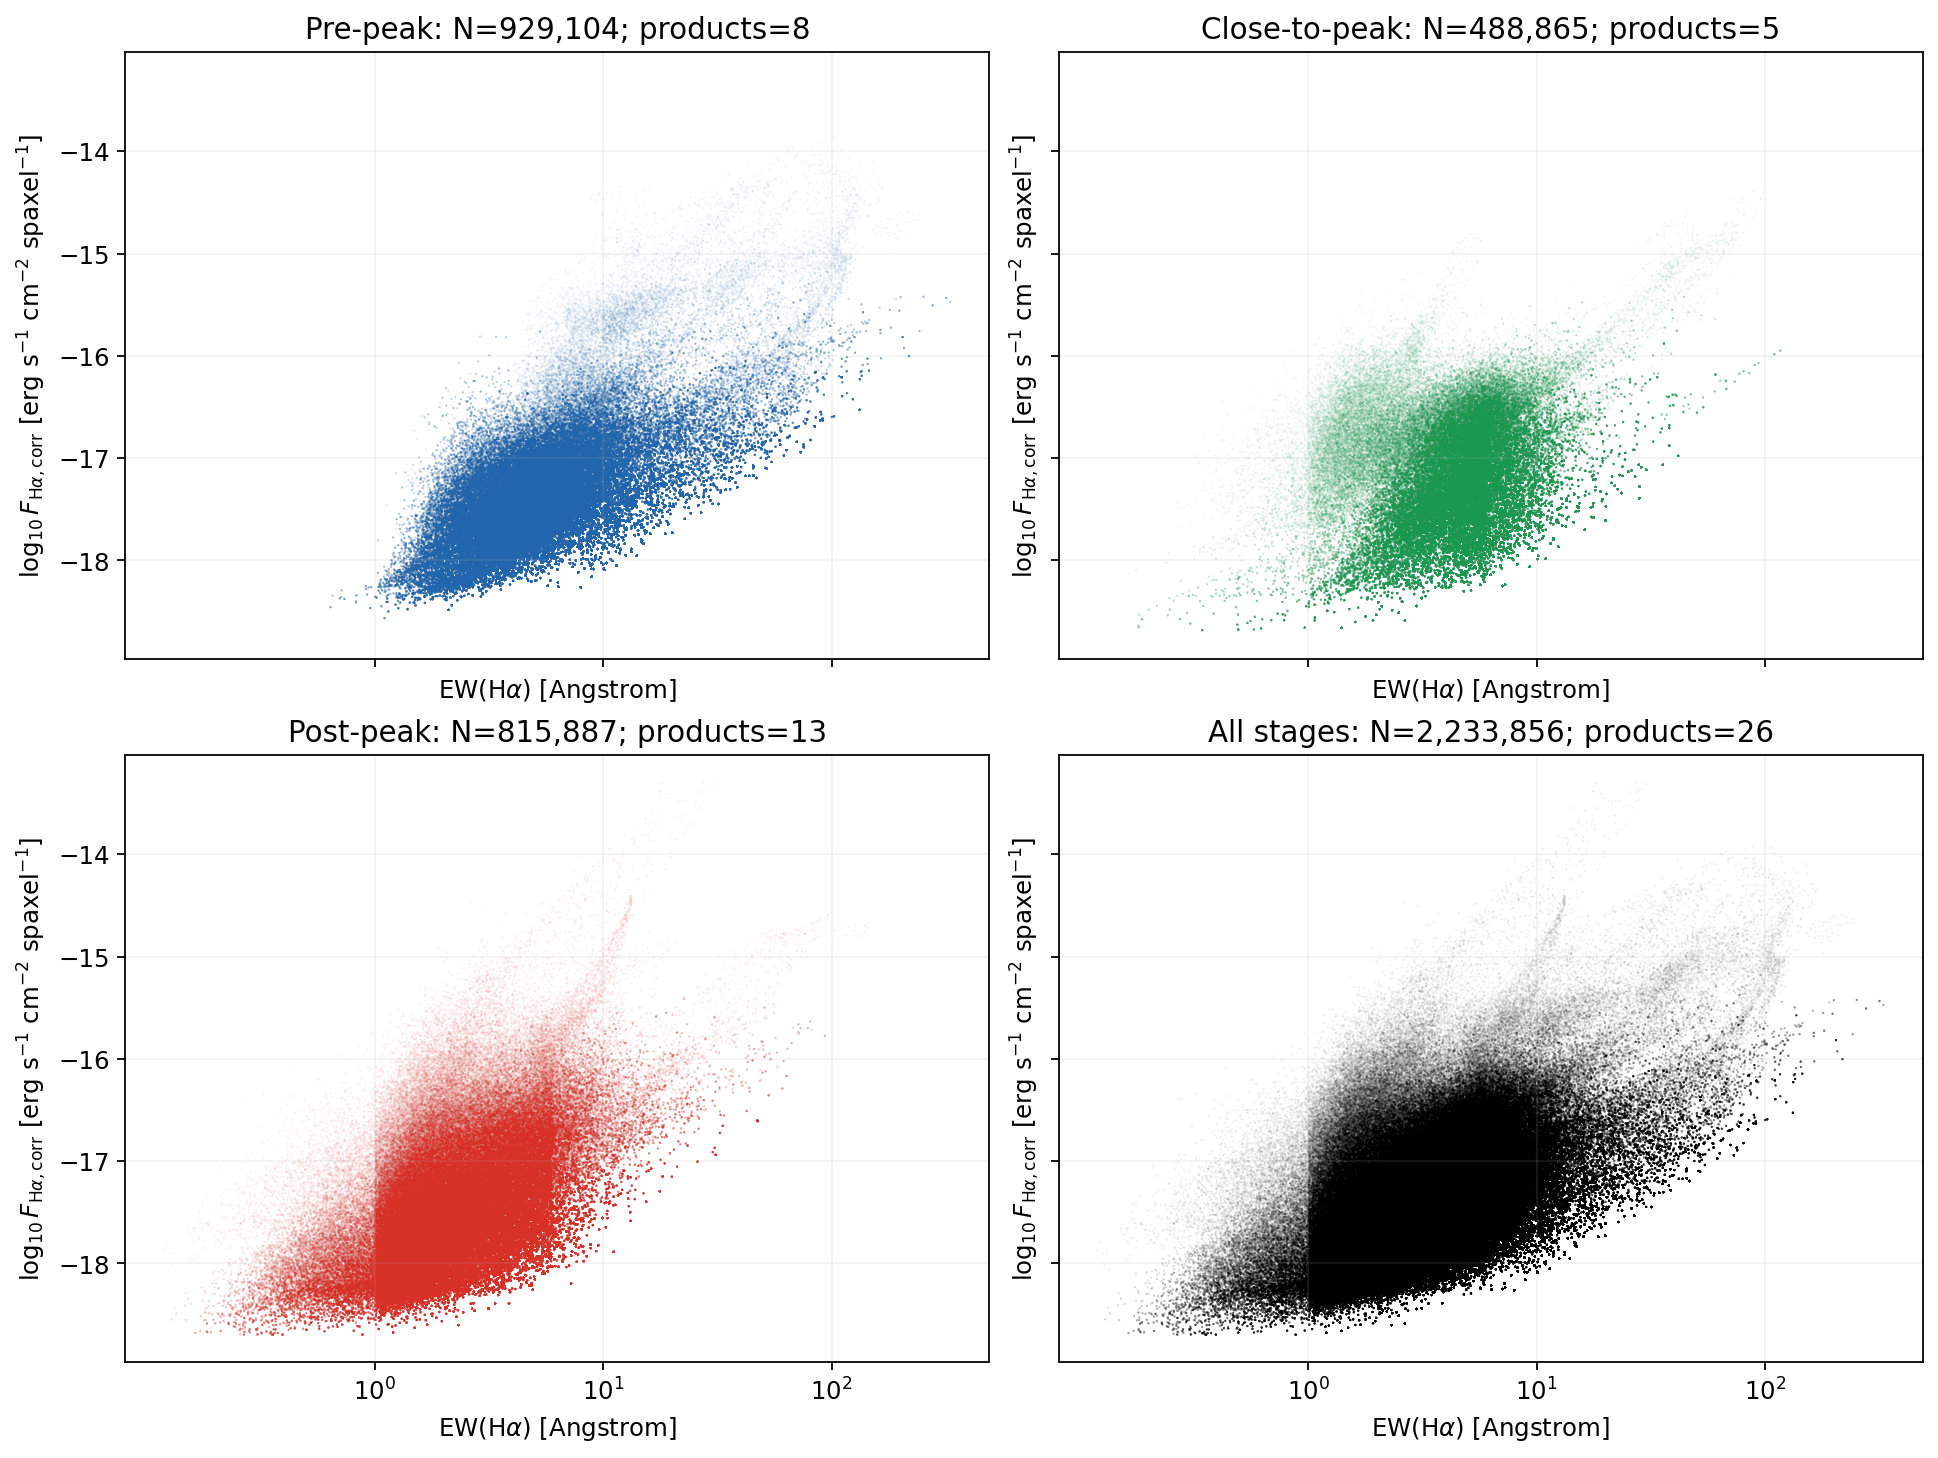

<Figure size 1440x1080 with 4 Axes>

In [7]:
LOGFLUX_LABEL = r'$\log_{10} F_{\mathrm{H}\alpha,\mathrm{corr}}$ [erg s$^{-1}$ cm$^{-2}$ spaxel$^{-1}$]'

def stage_subset(stage):
    return PIXELS if stage == 'all stages' else PIXELS.loc[PIXELS.stage.eq(stage)]

def paired_stage_scatter(xcolumn, xlabel, filename, xscale=None):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True,
                             constrained_layout=True)
    for ax, stage in zip(axes.flat, PANEL_ORDER):
        part = stage_subset(stage)
        part = part.loc[np.isfinite(part[xcolumn])]
        color = 'black' if stage == 'all stages' else STAGE_COLORS[stage]
        ax.scatter(part[xcolumn], np.log10(part.F_Ha_corr), s=1, alpha=.06,
                   color=color, rasterized=True, edgecolors='none')
        if xscale:
            ax.set_xscale('symlog', linthresh=1.)
        ax.set_title(f'{STAGE_LABELS[stage]}: N={len(part):,}; products={part.GALID.nunique()}')
        ax.set_xlabel(xlabel)
        ax.set_ylabel(LOGFLUX_LABEL)
        ax.grid(alpha=.15)
    finish_figure(fig, filename)

paired_stage_scatter('EW_Ha', r'EW(H$\alpha$) [Angstrom]',
                     '01_EW_vs_corrected_Halpha', xscale='symlog')

## 2. Nearest selected SF (EW>20 Angstrom) versus corrected Halpha flux
Only finite projected distances enter this panel. Galaxies without an SF reference remain in other analyses. An auxiliary log-like distance axis is unnecessary; distance is displayed linearly in kpc.

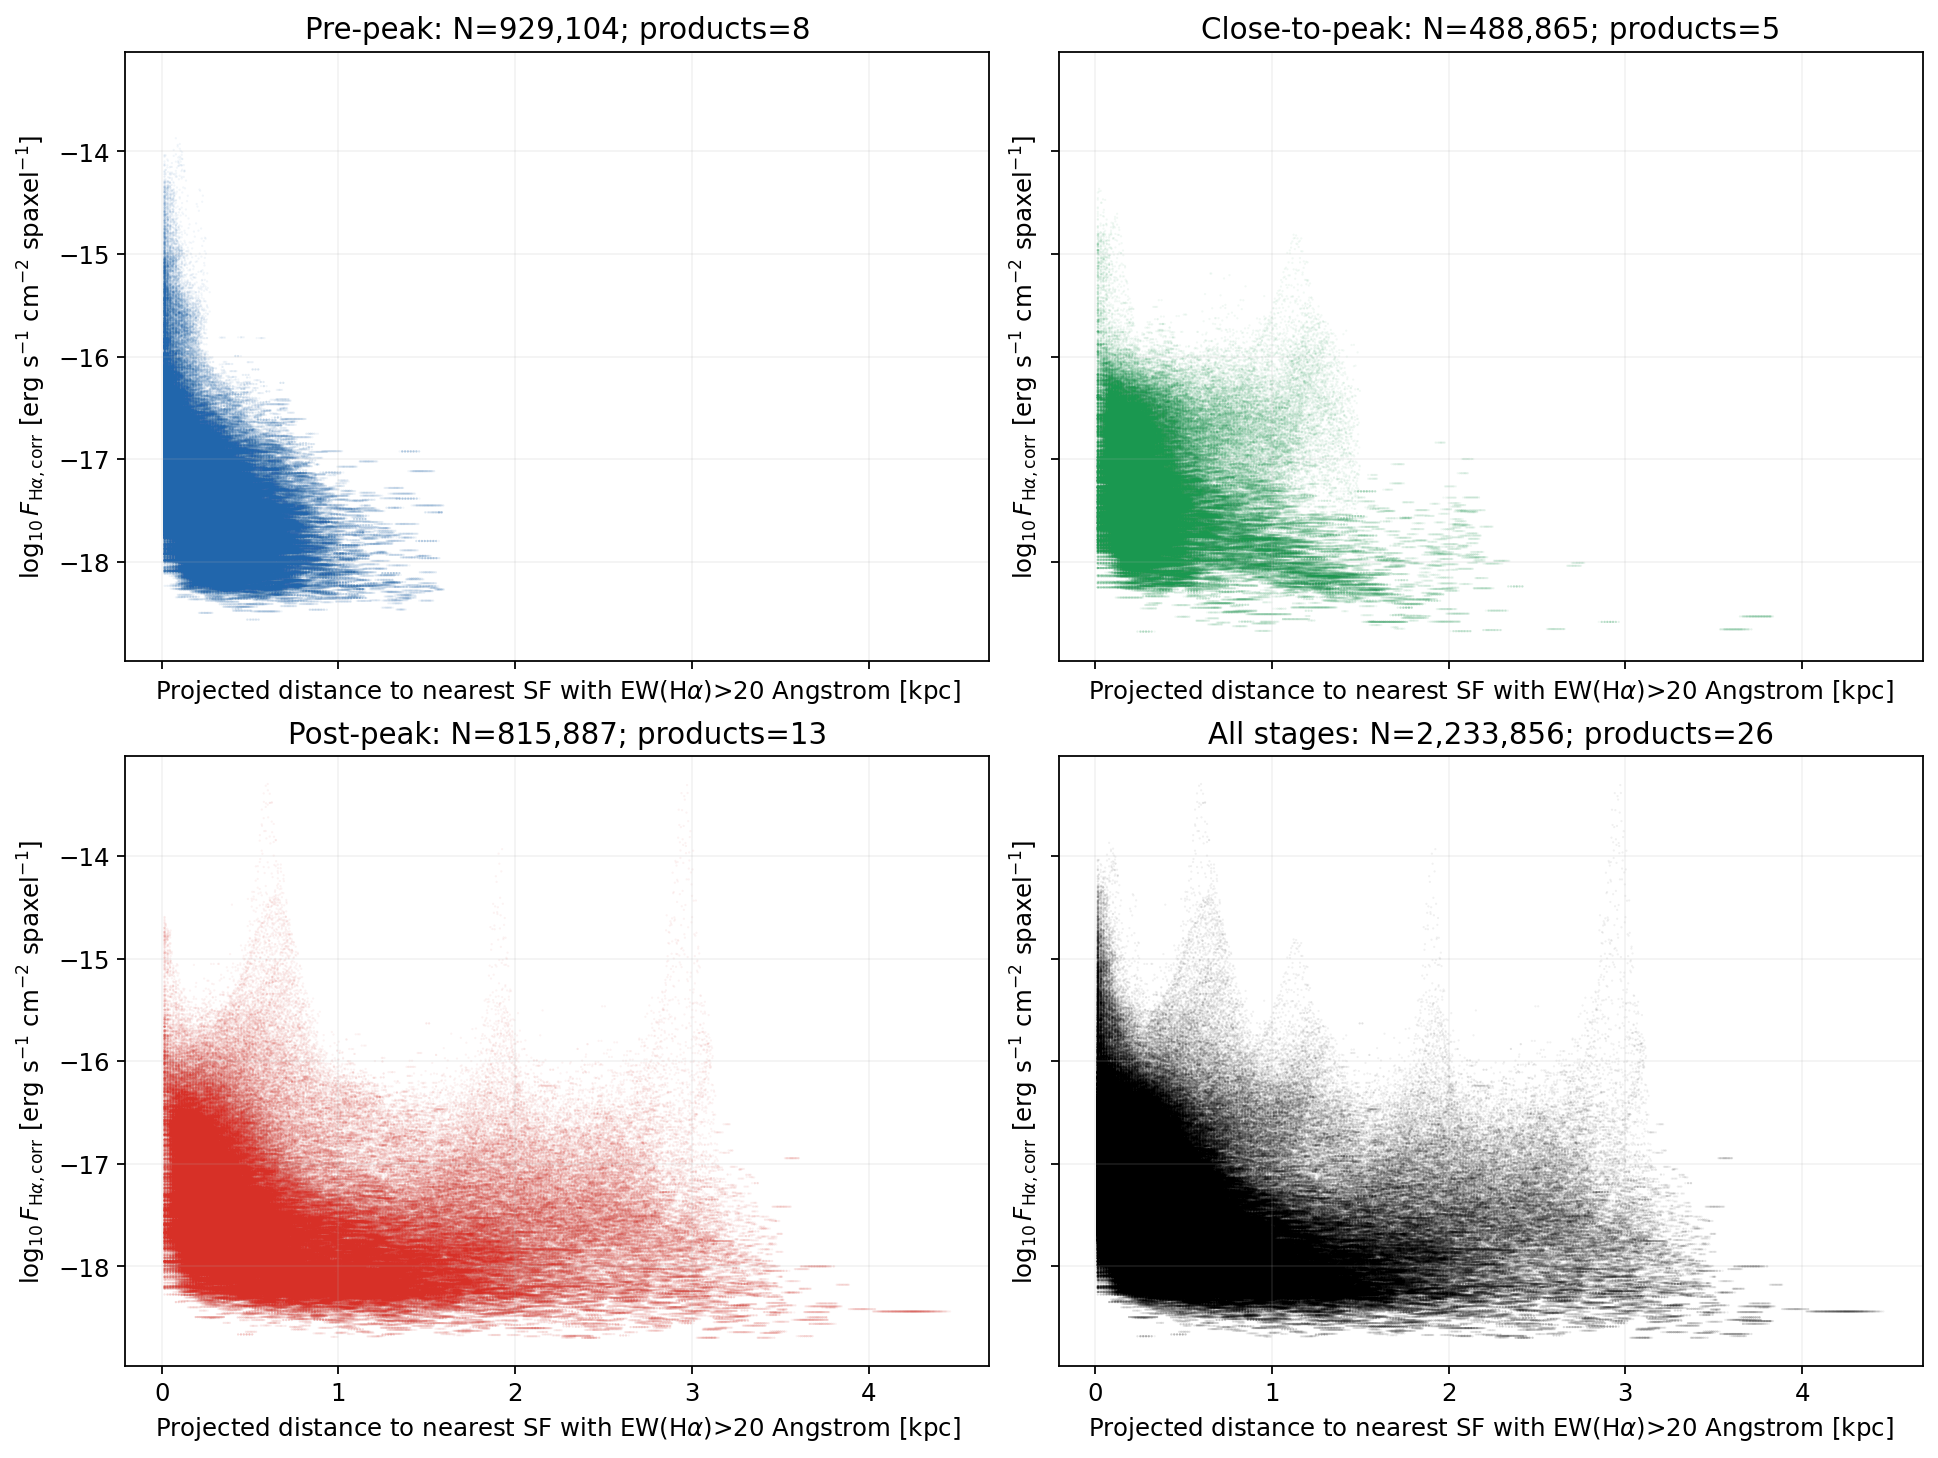

<Figure size 1440x1080 with 4 Axes>

In [8]:
paired_stage_scatter('distance_kpc', r'Projected distance to nearest SF with EW(H$\alpha$)>20 Angstrom [kpc]',
                     '02_distance_vs_corrected_Halpha')

## 3. Predicted HOLMES Halpha versus measured corrected Halpha
The x axis is the predicted **flux** assuming total stellar mass traces the old population; the y axis is the measured corrected flux in the same units/aperture. Below the 1:1 line means predicted>measured. Both log axes require positive predictions, so any zero predictions would be excluded from this scatter/histogram but retained in threshold fractions. No detection cut on sulfur is applied.

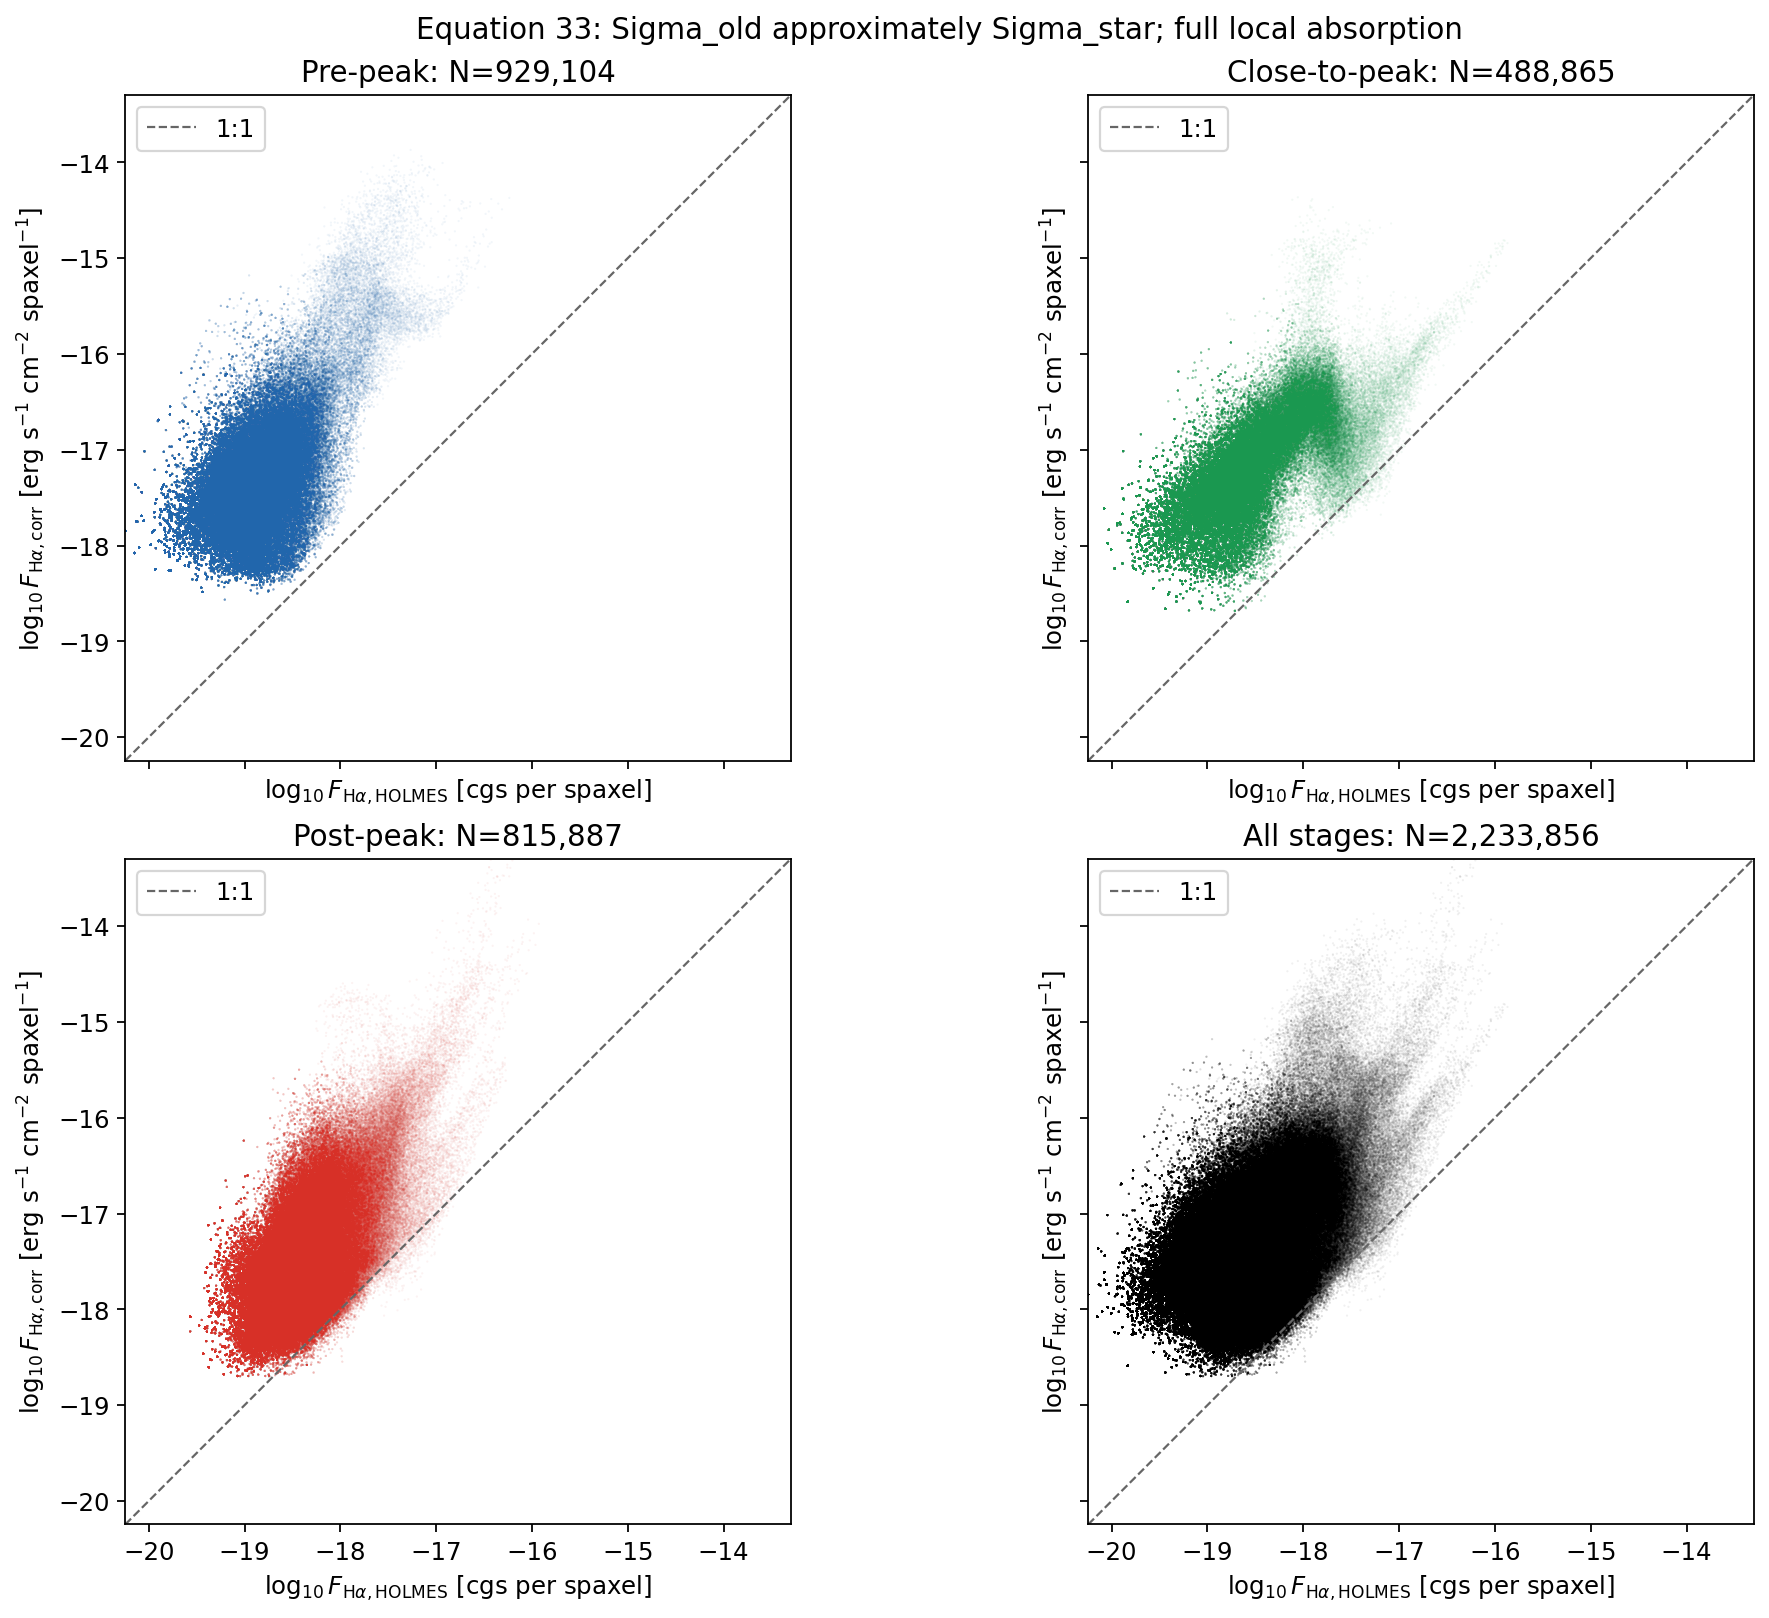

<Figure size 1440x1200 with 4 Axes>

In [9]:
positive_holmes = PIXELS.loc[np.isfinite(PIXELS.F_Ha_HOLMES) & (PIXELS.F_Ha_HOLMES > 0)]
if positive_holmes.empty:
    raise RuntimeError('No positive HOLMES predictions; inspect MEASUREMENT_QC')
lo = min(np.log10(positive_holmes.F_Ha_HOLMES).min(), np.log10(positive_holmes.F_Ha_corr).min())
hi = max(np.log10(positive_holmes.F_Ha_HOLMES).max(), np.log10(positive_holmes.F_Ha_corr).max())
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True, constrained_layout=True)
for ax, stage in zip(axes.flat, PANEL_ORDER):
    part = positive_holmes if stage == 'all stages' else positive_holmes.loc[positive_holmes.stage.eq(stage)]
    color = 'black' if stage == 'all stages' else STAGE_COLORS[stage]
    ax.scatter(np.log10(part.F_Ha_HOLMES), np.log10(part.F_Ha_corr),
               s=1, alpha=.06, color=color, edgecolors='none', rasterized=True)
    ax.plot([lo, hi], [lo, hi], color='0.4', ls='--', lw=1, label='1:1')
    ax.set(xlim=(lo, hi), ylim=(lo, hi), aspect='equal',
           title=f'{STAGE_LABELS[stage]}: N={len(part):,}',
           xlabel=r'$\log_{10} F_{\mathrm{H}\alpha,\mathrm{HOLMES}}$ [cgs per spaxel]', ylabel=LOGFLUX_LABEL)
    ax.legend(loc='upper left')
fig.suptitle('Equation 33: Sigma_old approximately Sigma_star; full local absorption')
finish_figure(fig, '03_predicted_HOLMES_vs_corrected_Halpha')

## Counts, fractions and required absorption
`N_HOLMES` is the finite nonnegative-prediction denominator; it includes zero predictions. `N_flux` is the parent positive-flux NSF count. The requested strict predicted>measured fraction is `fraction_gt_1` (equal values do not pass). Thresholds 0.1 and 0.5 describe budgets capable of 10% and 50% of the measured Halpha. Equal-galaxy fractions average the per-product fractions; pooled fractions weight each spaxel equally. Neither is a causal source decomposition.

In [10]:
def budget_summary(part):
    r = part.ratio_HOLMES.to_numpy()
    finite = np.isfinite(r) & (r >= 0)
    r = r[finite]
    out = dict(N_flux=len(part), N_HOLMES=len(r), N_zero=int((r == 0).sum()),
               N_products=part.GALID.nunique(), median_ratio=float(np.median(r)) if len(r) else np.nan)
    for threshold, suffix in ((.1, '0p1'), (.4, '0p4'), (.5, '0p5'), (1., '1')):
        out['N_gt_'+suffix] = int((r > threshold).sum())
        out['fraction_gt_'+suffix] = float(np.mean(r > threshold)) if len(r) else np.nan
    # Integrate only the paired NSF pixels carrying colours in the spatial maps.
    coloured = (np.isfinite(part.delta_logflux)
                & np.isfinite(part.F_Ha_HOLMES) & (part.F_Ha_HOLMES > 0)
                & np.isfinite(part.F_Ha_corr) & (part.F_Ha_corr > 0))
    paired = part.loc[coloured]
    holmes_sum = float(paired.F_Ha_HOLMES.sum())
    corrected_sum = float(paired.F_Ha_corr.sum())
    out.update(N_integrated_NSF=len(paired), sum_F_Ha_HOLMES=holmes_sum,
               sum_F_Ha_corr=corrected_sum,
               integrated_HOLMES_fraction=holmes_sum/corrected_sum if corrected_sum > 0 else np.nan)
    return out

GALAXY_BUDGET = pd.DataFrame([dict(GALID=g, stage=p.stage.iloc[0], **budget_summary(p))
    for g, p in PIXELS.groupby('GALID', sort=True, observed=True)])
STAGE_BUDGET = pd.DataFrame([dict(stage=stage, **budget_summary(stage_subset(stage)))
                            for stage in PANEL_ORDER])
EQUAL_GALAXY_BUDGET = GALAXY_BUDGET.groupby('stage', observed=True).agg(
    N_products_with_HOLMES=('fraction_gt_1', 'count'),
    mean_fraction_gt_0p1=('fraction_gt_0p1', 'mean'),
    mean_fraction_gt_0p4=('fraction_gt_0p4', 'mean'),
    mean_fraction_gt_0p5=('fraction_gt_0p5', 'mean'),
    mean_fraction_gt_1=('fraction_gt_1', 'mean'))
display(GALAXY_BUDGET)
display(STAGE_BUDGET)
display(EQUAL_GALAXY_BUDGET)
all_budget = STAGE_BUDGET.loc[STAGE_BUDGET.stage.eq('all stages')].iloc[0]
print(f"Requested count: {int(all_budget.N_gt_1):,}/{int(all_budget.N_HOLMES):,} "
      f"NSF spaxels ({all_budget.fraction_gt_1:.2%}) have predicted HOLMES > corrected Halpha.")
print('This is potential photon-budget sufficiency under the stated model, not an inferred physical contribution.')

Requested count: 7,200/2,233,856 NSF spaxels (0.32%) have predicted HOLMES > corrected Halpha.
This is potential photon-budget sufficiency under the stated model, not an inferred physical contribution.


        GALID          stage  ...  sum_F_Ha_corr  integrated_HOLMES_fraction
0      IC3392      post-peak  ...   7.581181e-14                    0.029040
1     NGC4064      post-peak  ...   5.808058e-13                    0.021343
2     NGC4189       pre-peak  ...   4.126379e-13                    0.014412
3     NGC4254       pre-peak  ...   2.085838e-12                    0.010725
4     NGC4293      post-peak  ...   1.111329e-12                    0.036228
5     NGC4294       pre-peak  ...   3.401676e-13                    0.008314
6     NGC4298  close-to-peak  ...   3.723468e-13                    0.018772
7     NGC4321       pre-peak  ...   3.366728e-12                    0.017520
8     NGC4351       pre-peak  ...   5.218796e-14                    0.019424
9     NGC4380      post-peak  ...   2.432727e-13                    0.062548
10    NGC4383       pre-peak  ...   2.152047e-12                    0.002563
11    NGC4394      post-peak  ...   1.276704e-13                    0.189007

           stage   N_flux  ...  sum_F_Ha_corr  integrated_HOLMES_fraction
0       pre-peak   929104  ...   1.240920e-11                    0.012621
1  close-to-peak   488865  ...   5.439042e-12                    0.043577
2      post-peak   815887  ...   1.050583e-11                    0.046314
3     all stages  2233856  ...   2.835407e-11                    0.031043

[4 rows x 18 columns]

               N_products_with_HOLMES  ...  mean_fraction_gt_1
stage                                  ...                    
close-to-peak                       5  ...            0.000871
post-peak                          13  ...            0.007557
pre-peak                            8  ...            0.000000

[3 rows x 5 columns]

## PDF of $F_{\rm HOLMES}/F_{\rm corr}$ and stage percentile table
The PDF uses $\Delta=\log_{10}(F_{\rm HOLMES}/F_{\rm corr})$ with common bins spanning all finite values. The **three coloured dashed lines mark the median delta of the corresponding infall stage**; there is no pooled median line or fixed-threshold reference line.

The table reports the 16th, 50th (median) and 84th percentiles of finite delta, and converts each endpoint to a linear percentage using $100\times10^{\Delta_p}$. The 16th--84th range describes the pooled-spaxel distribution, **not uncertainty on the median**. Strict ratio>0.1 and ratio>0.4 counts/fractions are shown side by side, using the same denominator. Values exactly equal to a threshold do not pass it. Its denominator includes finite nonnegative ratios; zero ratios cannot enter the logarithmic PDF/percentiles and are recorded in the saved summary. Spaxels are correlated by the PSF and spectral bins; these are descriptive summaries.

The PDF display is limited to -3 to 0 dex. The upper axis shows the corresponding linear ratio in percent (0.1%, 1%, 10%, 100%). All finite data still enter histogram normalization, percentiles and threshold statistics; limiting the displayed range does not renormalize the visible portion.

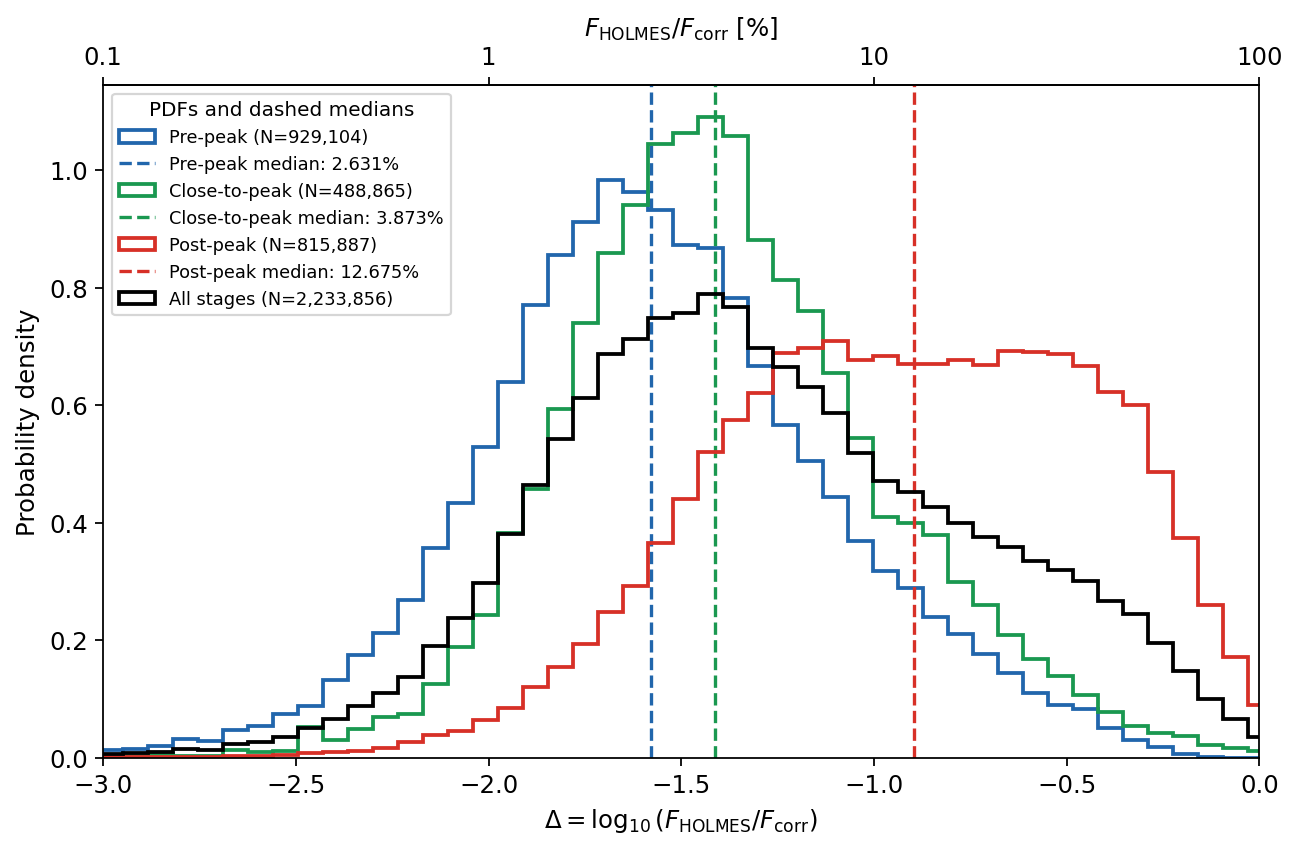

<Figure size 960x624 with 1 Axes>

In [11]:
delta_values = PIXELS.delta_logflux.to_numpy()
delta_values = delta_values[np.isfinite(delta_values)]
bins = np.linspace(delta_values.min()-.02, delta_values.max()+.02, 70)
fig, ax = plt.subplots(figsize=(8, 5.2), constrained_layout=True)
summary_rows = []
for stage in PANEL_ORDER:
    part = stage_subset(stage)
    ratios = part.ratio_HOLMES.to_numpy()
    ratios = ratios[np.isfinite(ratios) & (ratios >= 0)]
    logs = part.delta_logflux.to_numpy()
    logs = logs[np.isfinite(logs)]
    color = 'black' if stage == 'all stages' else STAGE_COLORS[stage]
    if len(logs):
        p16, median_delta, p84 = np.percentile(logs, [16, 50, 84])
        ax.hist(logs, bins=bins, density=True, histtype='step', color=color,
                lw=1.7, label=f'{STAGE_LABELS[stage]} (N={len(logs):,})')
        if stage in STAGE_ORDER:
            ax.axvline(median_delta, ls='--', color=color, lw=1.5,
                       label=f'{STAGE_LABELS[stage]} median: {100*10.**median_delta:.3f}%')
    else:
        p16 = median_delta = p84 = np.nan
    count_above = int((ratios > .1).sum())
    count_above_40 = int((ratios > .4).sum())
    summary_rows.append(dict(stage=stage, N_ratio=len(ratios), N_finite_delta=len(logs),
        N_zero_ratio=int((ratios == 0).sum()), delta_p16_dex=p16,
        median_delta_dex=median_delta, delta_p84_dex=p84,
        ratio_p16_percent=100*10.**p16, median_delta_as_percent=100*10.**median_delta,
        ratio_p84_percent=100*10.**p84,
        N_ratio_gt_10percent=count_above,
        NSF_percent_ratio_gt_10percent=100*count_above/len(ratios) if len(ratios) else np.nan,
        N_ratio_gt_40percent=count_above_40,
        NSF_percent_ratio_gt_40percent=100*count_above_40/len(ratios) if len(ratios) else np.nan))
ax.set(xlabel=r'$\Delta=\log_{10}(F_{\mathrm{HOLMES}}/F_{\mathrm{corr}})$',
       ylabel='Probability density')
# Restrict display only; the PDF normalization and percentile table use all finite data.
ax.set_xlim(-3., 0.)
top_xaxis = ax.secondary_xaxis('top', functions=(
    lambda delta: np.power(10., np.asarray(delta) + 2.),
    lambda percent: np.log10(np.maximum(np.asarray(percent), np.finfo(float).tiny)) - 2.,
))
top_xaxis.set_xticks([.1, 1., 10., 100.], labels=['0.1', '1', '10', '100'])
top_xaxis.set_xlabel(r'$F_{\mathrm{HOLMES}}/F_{\mathrm{corr}}$ [%]')
top_xaxis.minorticks_off()
ax.legend(fontsize=8, loc='upper left', title='PDFs and dashed medians', title_fontsize=9)
finish_figure(fig, '04_HOLMES_ratio_distributions')
RATIO_STAGE_SUMMARY = pd.DataFrame(summary_rows)

PERCENTILE_TABLE = pd.DataFrame({
    'Stage': RATIO_STAGE_SUMMARY.stage.map(STAGE_LABELS),
    'Delta p16 [dex]': RATIO_STAGE_SUMMARY.delta_p16_dex,
    'Delta median [dex]': RATIO_STAGE_SUMMARY.median_delta_dex,
    'Delta p84 [dex]': RATIO_STAGE_SUMMARY.delta_p84_dex,
    'Ratio p16 [%]': RATIO_STAGE_SUMMARY.ratio_p16_percent,
    'Ratio median [%]': RATIO_STAGE_SUMMARY.median_delta_as_percent,
    'Ratio p84 [%]': RATIO_STAGE_SUMMARY.ratio_p84_percent,
    'NSF ratio >10% [n/N]': [f'{r.N_ratio_gt_10percent:,}/{r.N_ratio:,}'
                            for r in RATIO_STAGE_SUMMARY.itertuples()],
    'NSF ratio >10% [%]': RATIO_STAGE_SUMMARY.NSF_percent_ratio_gt_10percent,
    'NSF ratio >40% [n/N]': [f'{r.N_ratio_gt_40percent:,}/{r.N_ratio:,}'
                            for r in RATIO_STAGE_SUMMARY.itertuples()],
    'NSF ratio >40% [%]': RATIO_STAGE_SUMMARY.NSF_percent_ratio_gt_40percent,
})
display(PERCENTILE_TABLE.style.hide(axis='index').format({
    column: '{:.3f}' for column in PERCENTILE_TABLE.select_dtypes(include='number').columns
}, na_rep='--'))
if SAVE_OUTPUTS:
    RATIO_STAGE_SUMMARY.to_csv(ASSET_DIR / 'ratio_stage_summary.csv', index=False)

## Controlled PDFs: local stellar mass density and radius

Repeat cell 20 within **local stellar surface density** $\log_{10}(\Sigma_*/[M_\odot\,\mathrm{kpc}^{-2}])$ and deprojected elliptical $R/R_e$ bins. Mass here is the inherited `LOGMASS_SURFACE_DENSITY` map, not total galaxy mass or the per-spaxel `LOGMSTAR` used in the HOLMES prediction. Radius uses the existing geometry (minimum component $R/R_e$ for combined products).

The first figure compares mass bins with all radii; the second compares radius bins with all masses. The third controls both together: **columns = mass bins, rows = radius bins**. Edit the edges below; the outer bins retain the full finite sample. Intervals are lower-inclusive and upper-exclusive. Missing bin coordinates are counted explicitly.

Each panel repeats the stage PDFs plus the black pooled PDF, and coloured dashed stage medians. Common histogram bins come from cell 20; each PDF normalizes over all its finite delta values, including values outside the displayed -3 to 0 dex. Empty selections remain labelled. Tables include product counts, percentiles, zero-ratio counts, and strict >10% and >40% counts with finite nonnegative-ratio denominators. These are pooled-spaxel descriptive comparisons; binning does not provide equal-galaxy weighting, statistical independence, or causal source fractions. In particular, local mass also enters the HOLMES numerator.


In [12]:
# Editable bin edges; broad defaults retain tails rather than imposing a new cut.
LOCAL_MASS_BIN_EDGES = np.array([-np.inf, 8., 9., np.inf])
RADIAL_BIN_EDGES = np.array([0., .5, 1., np.inf])

def bin_memberships(column, edges, symbol):
    edges = np.asarray(edges, dtype=float)
    if len(edges) < 2 or np.isnan(edges).any() or not np.all(np.diff(edges) > 0):
        raise ValueError('Bin edges must increase strictly and contain no NaN')
    values = PIXELS[column].to_numpy()
    result = []
    for lower, upper in zip(edges[:-1], edges[1:]):
        mask = np.isfinite(values) & (values >= lower) & (values < upper)
        label = (f'{symbol} < {upper:g}' if np.isneginf(lower) else
                 f'{symbol} >= {lower:g}' if np.isposinf(upper) else
                 f'{lower:g} <= {symbol} < {upper:g}')
        result.append(dict(lower=lower, upper=upper, label=label, mask=mask))
    membership = np.sum([b['mask'] for b in result], axis=0)
    expected = np.isfinite(values) & (values >= edges[0]) & (values < edges[-1])
    assert np.array_equal(membership, expected.astype(int))
    print(f'{column}: {expected.sum():,}/{len(PIXELS):,} assigned; '
          f'{(~np.isfinite(values)).sum():,} nonfinite; '
          f'{(np.isfinite(values) & ~expected).sum():,} outside edges')
    return result

MASS_PDF_BINS = bin_memberships('log_sigma_star', LOCAL_MASS_BIN_EDGES, 'log Sigma*')
RADIUS_PDF_BINS = bin_memberships('radius_re', RADIAL_BIN_EDGES, 'R/Re')

def controlled_pdf(ax, mask, title, metadata):
    rows = []
    selected = PIXELS.loc[mask]
    for stage in PANEL_ORDER:
        part = selected if stage == 'all stages' else selected.loc[selected.stage.eq(stage)]
        logs = part.delta_logflux.to_numpy()
        logs = logs[np.isfinite(logs)]
        ratios = part.ratio_HOLMES.to_numpy()
        ratios = ratios[np.isfinite(ratios) & (ratios >= 0)]
        color = 'black' if stage == 'all stages' else STAGE_COLORS[stage]
        p16, median, p84 = np.percentile(logs, [16, 50, 84]) if len(logs) else [np.nan]*3
        label = f'{STAGE_LABELS[stage]}: N={len(logs):,}, G={part.GALID.nunique()}'
        if len(logs):
            ax.hist(logs, bins=bins, density=True, histtype='step', color=color,
                    lw=1.7, label=label)
            if stage in STAGE_ORDER:
                ax.axvline(median, color=color, ls='--', lw=1.3,
                           label=f'Median: {100*10.**median:.2f}%')
        else:
            ax.plot([], [], color=color, label=label + ' (empty)')
        row = dict(**metadata, stage=stage, N_flux=len(part),
                   N_products=part.GALID.nunique(),
                   N_products_finite_delta=part.loc[np.isfinite(part.delta_logflux), 'GALID'].nunique(),
                   N_ratio=len(ratios), N_finite_delta=len(logs),
                   N_zero_ratio=int((ratios == 0).sum()),
                   delta_p16_dex=p16, median_delta_dex=median, delta_p84_dex=p84,
                   ratio_p16_percent=100*10.**p16, median_delta_as_percent=100*10.**median,
                   ratio_p84_percent=100*10.**p84)
        for threshold, name in ((.1, '10'), (.4, '40')):
            count = int((ratios > threshold).sum())
            row['N_ratio_gt_'+name+'percent'] = count
            row['NSF_percent_ratio_gt_'+name+'percent'] = 100*count/len(ratios) if len(ratios) else np.nan
        rows.append(row)
    ax.set(title=title, xlim=(-3., 0.),
           xlabel=r'$\Delta=\log_{10}(F_{\mathrm{HOLMES}}/F_{\mathrm{corr}})$',
           ylabel='Probability density')
    top = ax.secondary_xaxis('top', functions=(
        lambda delta: np.power(10., np.asarray(delta)+2.),
        lambda percent: np.log10(np.maximum(np.asarray(percent), np.finfo(float).tiny))-2.))
    top.set_xticks([.1, 1., 10., 100.], labels=['0.1', '1', '10', '100'])
    top.set_xlabel('HOLMES / corrected Halpha [%]', fontsize=9)
    top.minorticks_off()
    ax.legend(fontsize=7, loc='upper left')
    if not np.isfinite(selected.delta_logflux).any():
        ax.text(.5, .5, 'No finite delta', transform=ax.transAxes, ha='center')
    return rows

def show_controlled_summary(rows, filename):
    table = pd.DataFrame(rows)
    display(table)
    if SAVE_OUTPUTS:
        table.to_csv(ASSET_DIR / (filename+'.csv'), index=False)
    return table


log_sigma_star: 2,233,856/2,233,856 assigned; 0 nonfinite; 0 outside edges
radius_re: 2,233,856/2,233,856 assigned; 0 nonfinite; 0 outside edges


### Local stellar surface density bins (all radii)

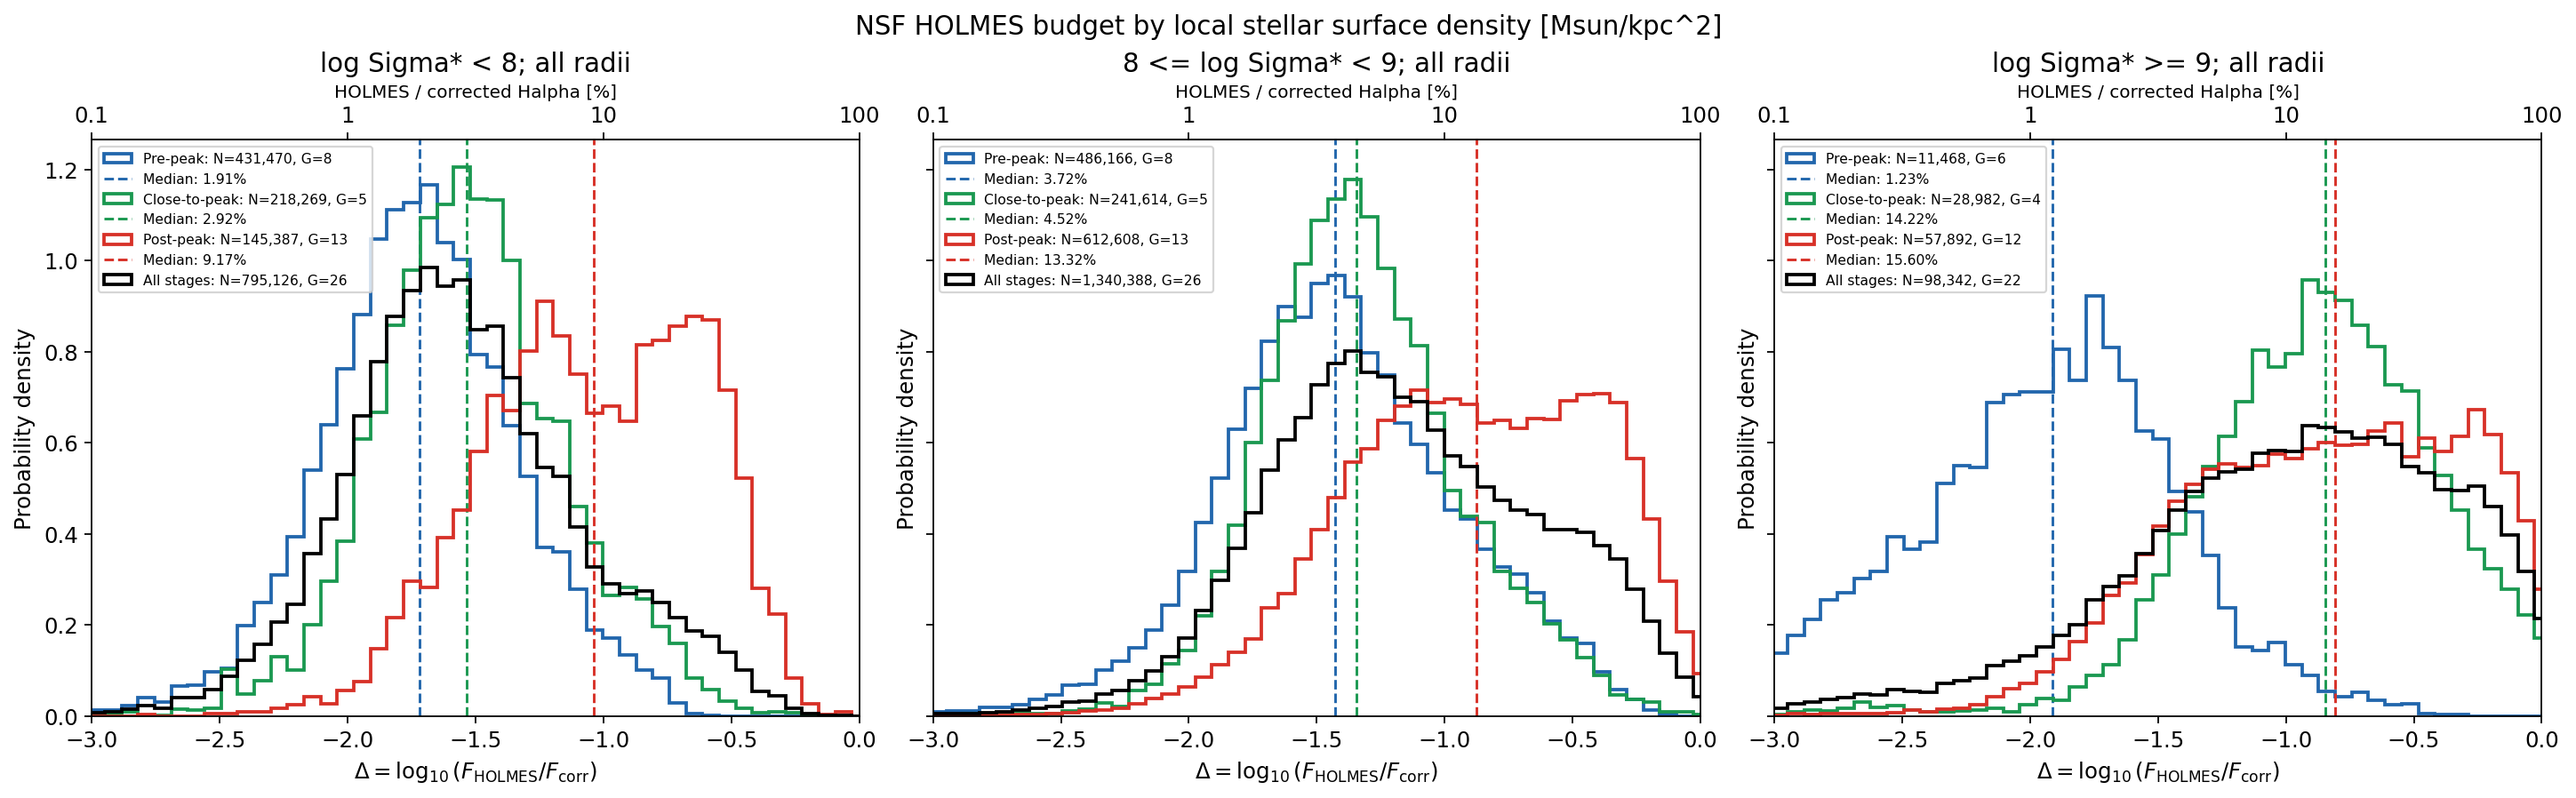

<Figure size 2160x660 with 3 Axes>

    mass_lower  ...  NSF_percent_ratio_gt_40percent
0         -inf  ...                        0.000000
1         -inf  ...                        0.138361
2         -inf  ...                        3.406082
3         -inf  ...                        0.660776
4          8.0  ...                        1.106412
5          8.0  ...                        1.251997
6          8.0  ...                       18.325259
7          8.0  ...                        9.002319
8          9.0  ...                        0.017440
9          9.0  ...                       15.143882
10         9.0  ...                       25.317833
11         9.0  ...                       19.369140

[12 rows x 19 columns]

In [13]:
fig, axes = plt.subplots(1, len(MASS_PDF_BINS), figsize=(6*len(MASS_PDF_BINS), 5.5),
                         squeeze=False, sharex=True, sharey=True, constrained_layout=True)
rows = []
for ax, mass_bin in zip(axes.flat, MASS_PDF_BINS):
    rows.extend(controlled_pdf(ax, mass_bin['mask'], mass_bin['label']+'; all radii',
                dict(mass_lower=mass_bin['lower'], mass_upper=mass_bin['upper'])))
fig.suptitle('NSF HOLMES budget by local stellar surface density [Msun/kpc^2]')
finish_figure(fig, '04a_HOLMES_ratio_by_local_mass')
RATIO_LOCAL_MASS_SUMMARY = show_controlled_summary(rows, 'ratio_local_mass_summary')


### Radius bins (all local stellar masses)

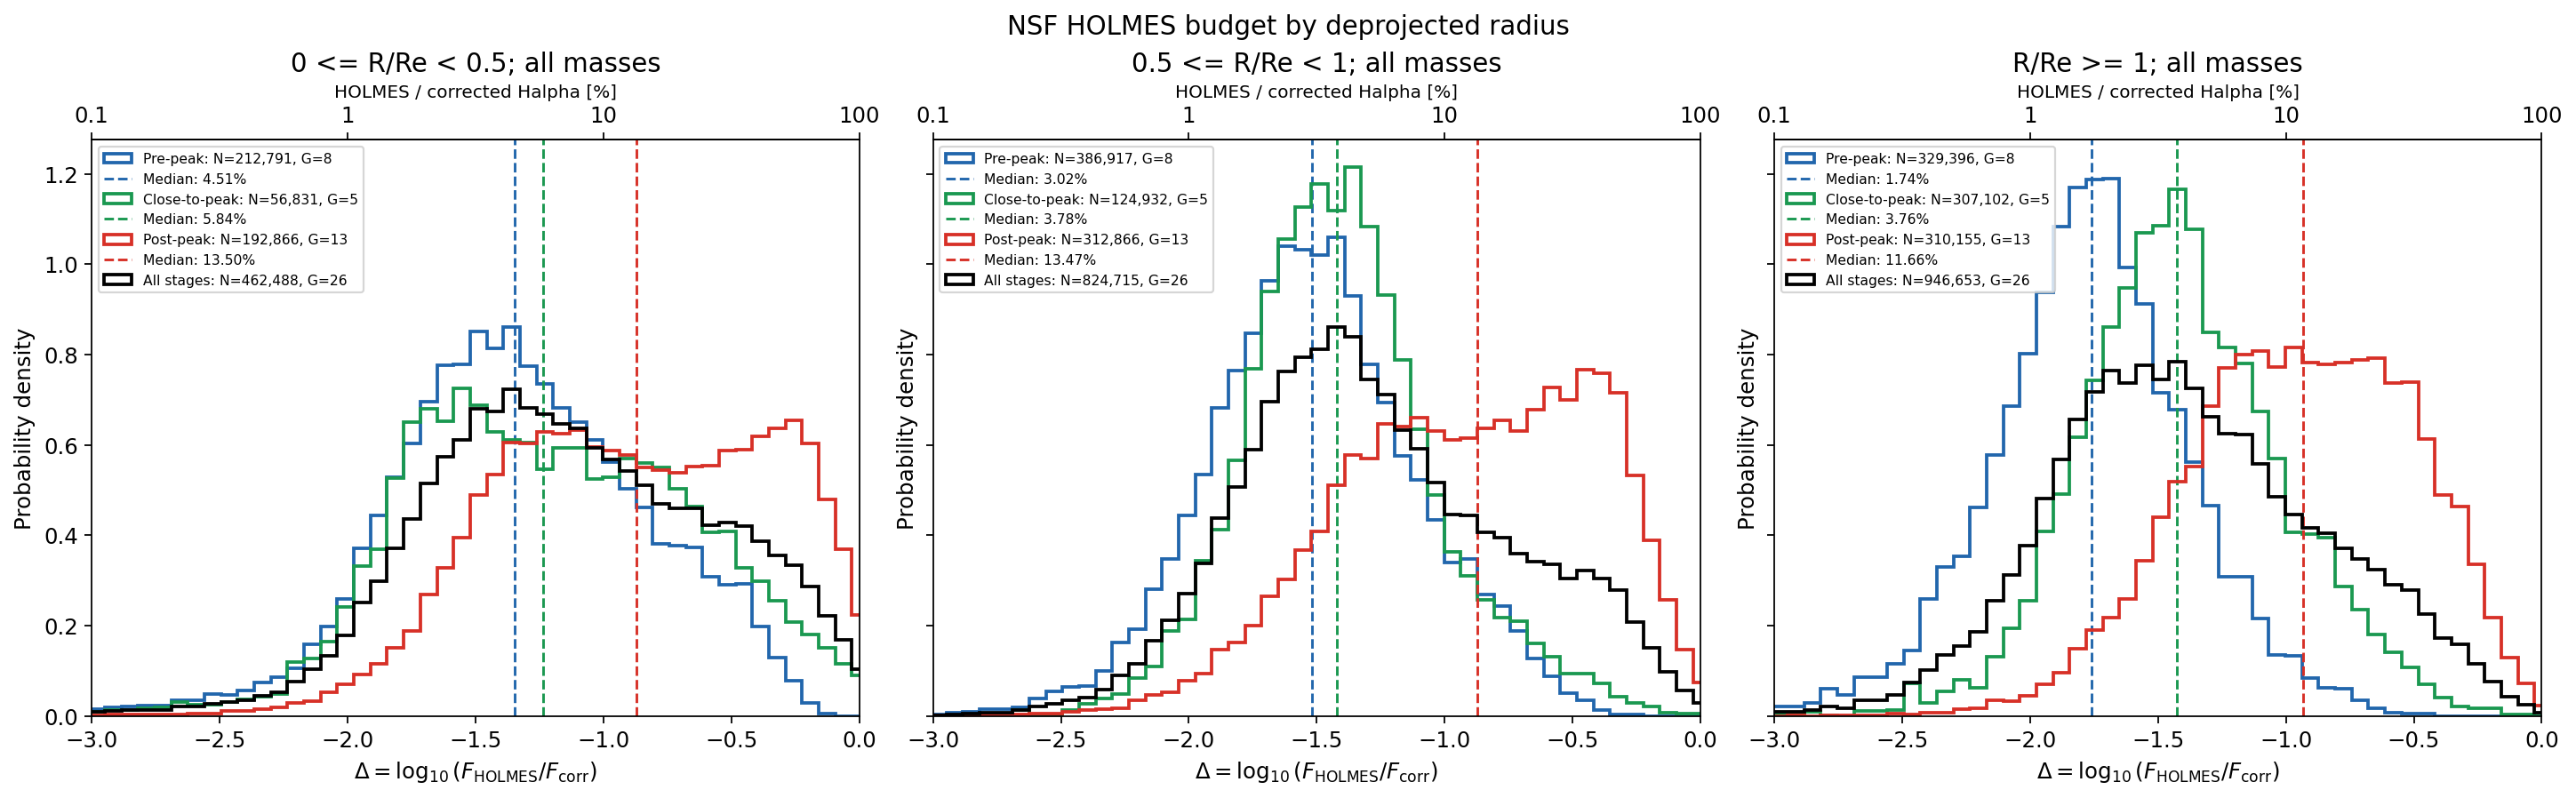

<Figure size 2160x660 with 3 Axes>

    radius_lower  ...  NSF_percent_ratio_gt_40percent
0            0.0  ...                        2.398128
1            0.0  ...                        8.336999
2            0.0  ...                       23.526179
3            0.0  ...                       11.938688
4            0.5  ...                        0.071850
5            0.5  ...                        1.037364
6            0.5  ...                       17.541376
7            0.5  ...                        6.845395
8            1.0  ...                        0.000000
9            1.0  ...                        0.547701
10           1.0  ...                       10.193613
11           1.0  ...                        3.517445

[12 rows x 19 columns]

In [14]:
fig, axes = plt.subplots(1, len(RADIUS_PDF_BINS), figsize=(6*len(RADIUS_PDF_BINS), 5.5),
                         squeeze=False, sharex=True, sharey=True, constrained_layout=True)
rows = []
for ax, radial_bin in zip(axes.flat, RADIUS_PDF_BINS):
    rows.extend(controlled_pdf(ax, radial_bin['mask'], radial_bin['label']+'; all masses',
                dict(radius_lower=radial_bin['lower'], radius_upper=radial_bin['upper'])))
fig.suptitle('NSF HOLMES budget by deprojected radius')
finish_figure(fig, '04b_HOLMES_ratio_by_radius')
RATIO_RADIUS_SUMMARY = show_controlled_summary(rows, 'ratio_radius_summary')


### Joint control of local stellar surface density and radius

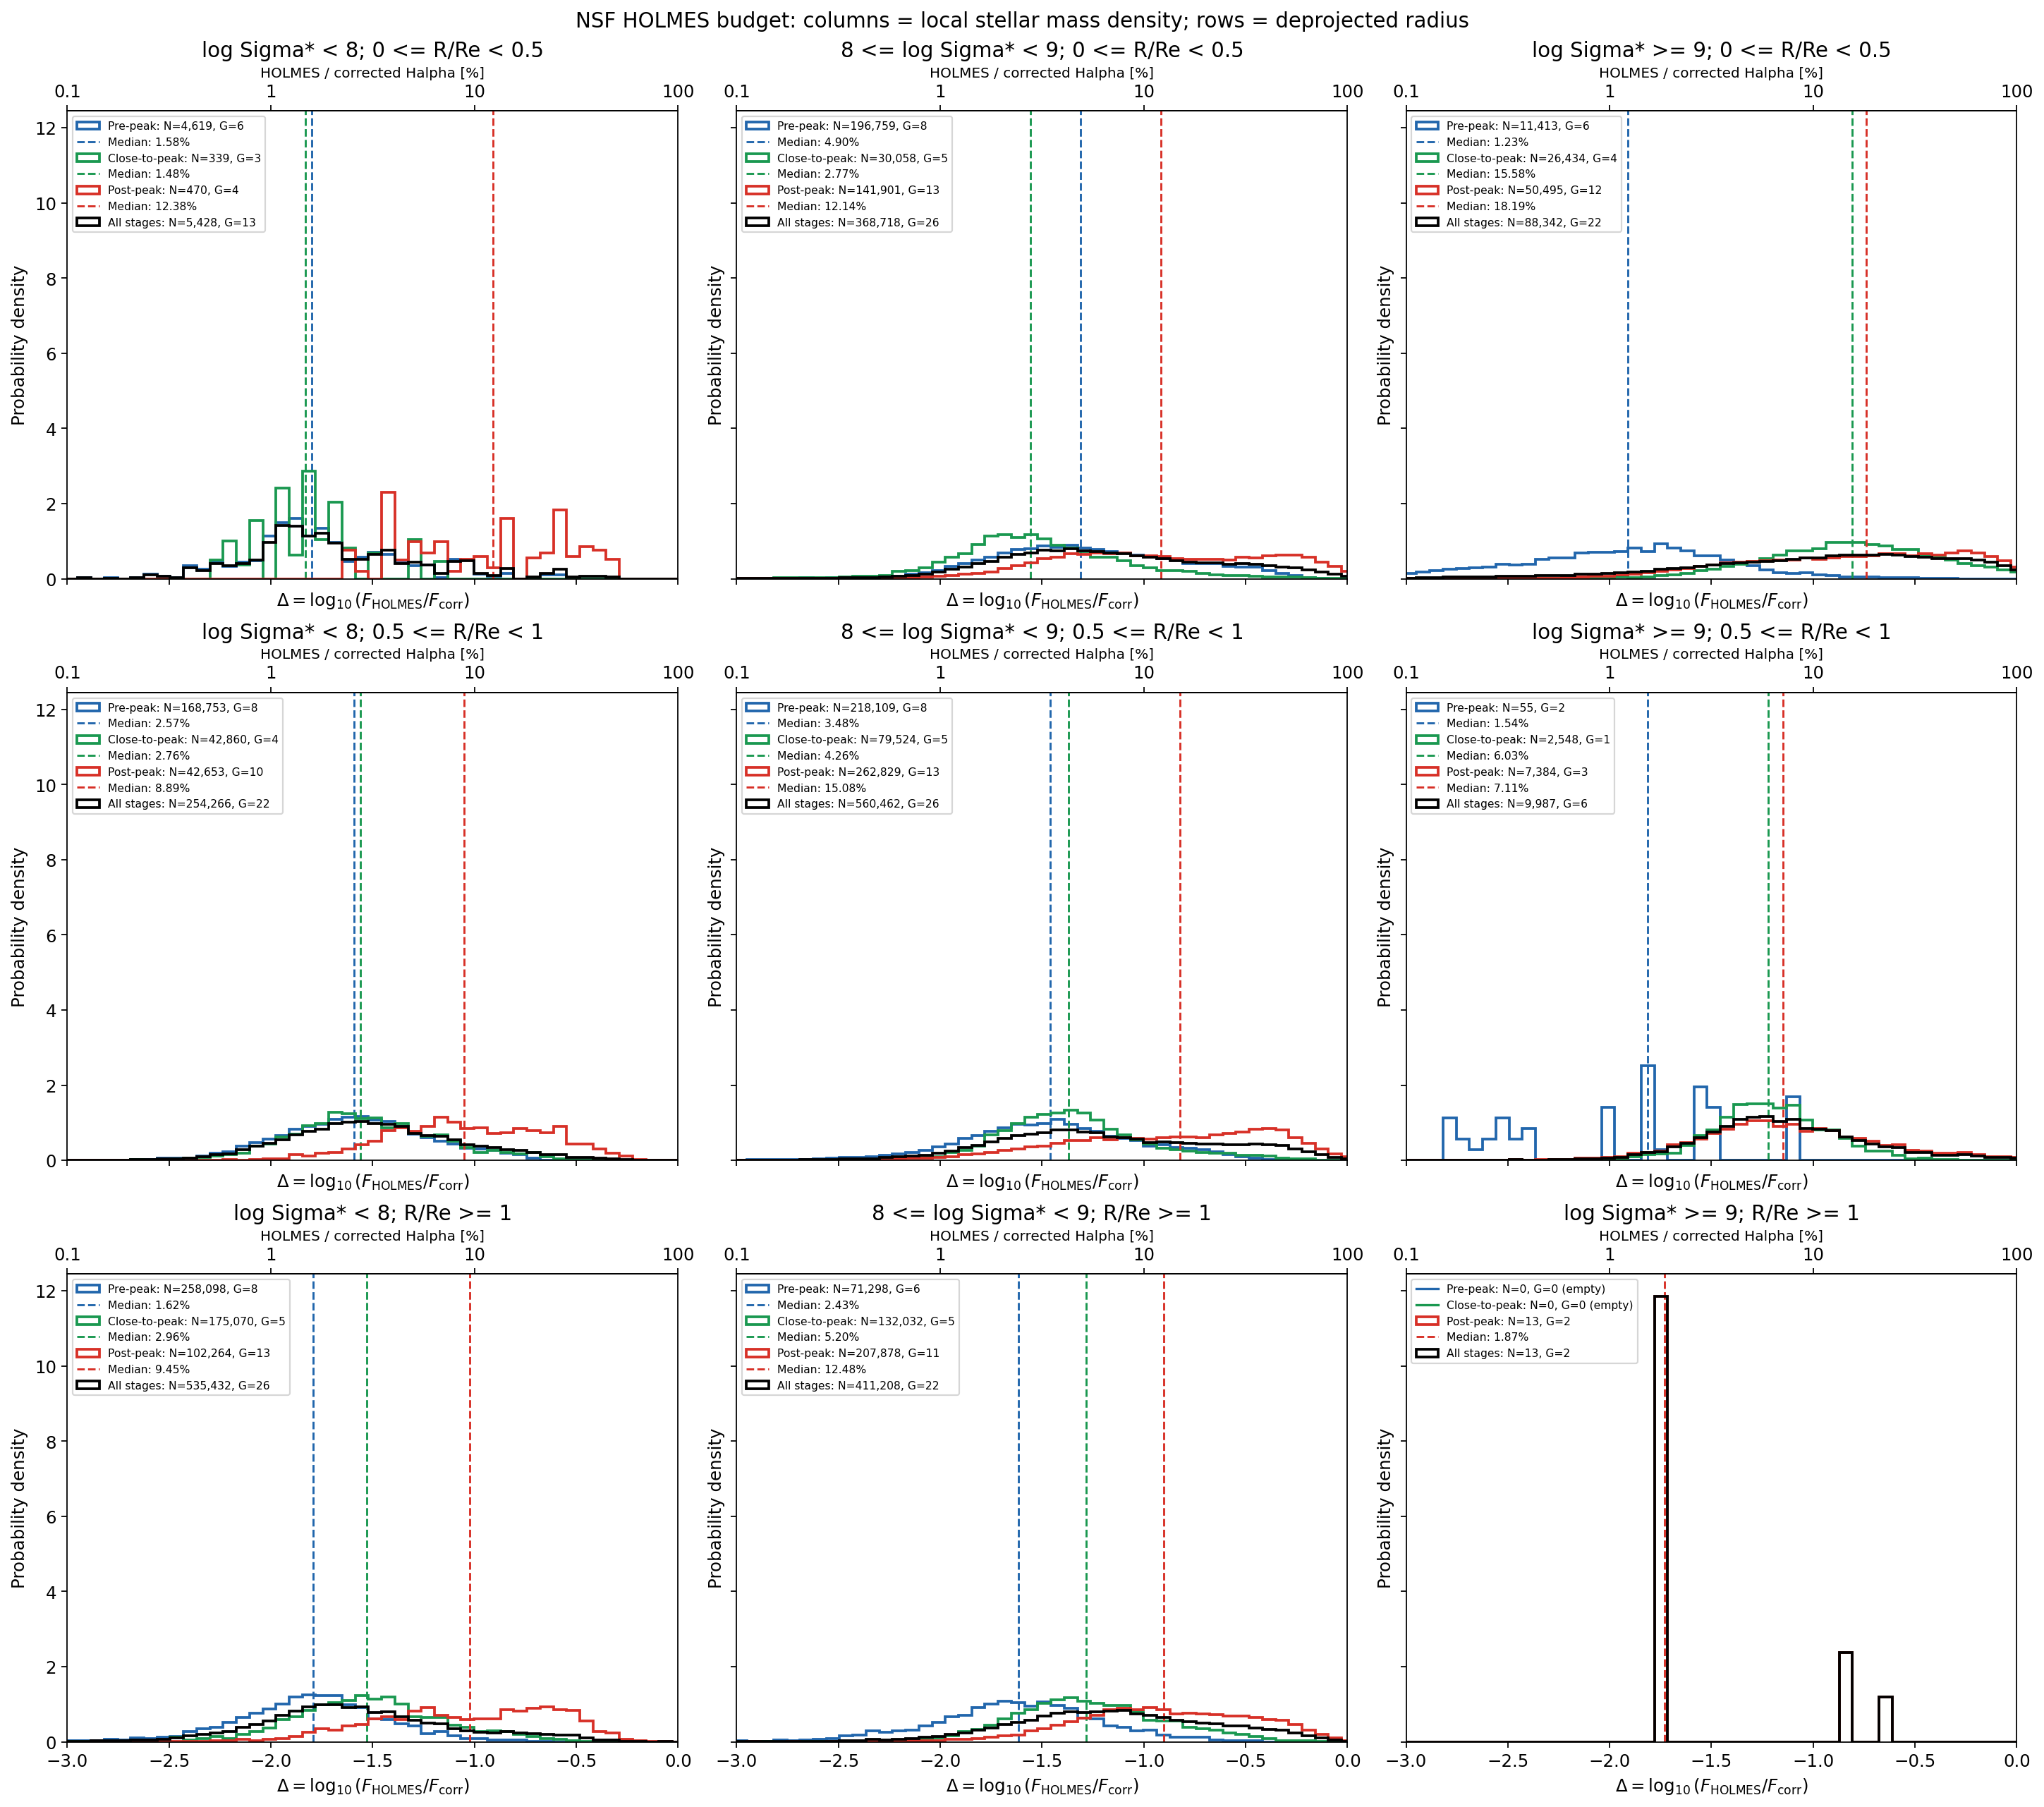

PASS: disjoint joint bins cover 2,233,856/2,233,856 NSF spaxels


<Figure size 2160x1908 with 9 Axes>

    mass_lower  ...  NSF_percent_ratio_gt_40percent
0         -inf  ...                        0.000000
1         -inf  ...                        0.000000
2         -inf  ...                        5.319149
3         -inf  ...                        0.460575
4          8.0  ...                        2.592512
5          8.0  ...                        1.181050
6          8.0  ...                       21.972361
7          8.0  ...                        9.935777
8          9.0  ...                        0.017524
9          9.0  ...                       16.580919
10         9.0  ...                       28.062184
11         9.0  ...                       21.003600
12        -inf  ...                        0.000000
13        -inf  ...                        0.072329
14        -inf  ...                        3.608187
15        -inf  ...                        0.617464
16         8.0  ...                        0.127459
17         8.0  ...                        1.583170
18         8

In [15]:
fig, axes = plt.subplots(len(RADIUS_PDF_BINS), len(MASS_PDF_BINS),
                         figsize=(6*len(MASS_PDF_BINS), 5.3*len(RADIUS_PDF_BINS)),
                         squeeze=False, sharex=True, sharey=True, constrained_layout=True)
rows = []
joint_membership = np.zeros(len(PIXELS), dtype=int)
for i, radial_bin in enumerate(RADIUS_PDF_BINS):
    for j, mass_bin in enumerate(MASS_PDF_BINS):
        mask = radial_bin['mask'] & mass_bin['mask']
        joint_membership += mask.astype(int)
        rows.extend(controlled_pdf(axes[i, j], mask,
                    mass_bin['label']+'; '+radial_bin['label'],
                    dict(mass_lower=mass_bin['lower'], mass_upper=mass_bin['upper'],
                         radius_lower=radial_bin['lower'], radius_upper=radial_bin['upper'])))
expected_joint = (np.logical_or.reduce([b['mask'] for b in MASS_PDF_BINS])
                  & np.logical_or.reduce([b['mask'] for b in RADIUS_PDF_BINS]))
assert np.array_equal(joint_membership, expected_joint.astype(int))
fig.suptitle('NSF HOLMES budget: columns = local stellar mass density; rows = deprojected radius')
finish_figure(fig, '04c_HOLMES_ratio_by_local_mass_and_radius')
RATIO_MASS_RADIUS_SUMMARY = show_controlled_summary(rows, 'ratio_local_mass_radius_summary')
assert RATIO_MASS_RADIUS_SUMMARY.loc[
    RATIO_MASS_RADIUS_SUMMARY.stage.eq('all stages'), 'N_flux'].sum() == expected_joint.sum()
print(f'PASS: disjoint joint bins cover {expected_joint.sum():,}/{len(PIXELS):,} NSF spaxels')


## 4. Spatial NSF ratios with SF/ND context
NSF is coloured by $\Delta=\log_{10}(F_{\rm HOLMES}/F_{\rm corr})$, using `coolwarm` from -2 dex (1%) to 0 dex (100%); the midpoint is -1 dex (10%). Dark gray denotes **all selected SF spaxels**, and light gray denotes **ND (Balmer non-detections)**. The inherited categories are unchanged; the dark-gray SF layer is not restricted to the EW>20 reference subset. Every category shown passes SNR_POSTFIT>25, and all products satisfy inclination<80 deg. Masked/out-of-footprint and quality-rejected pixels remain blank; they are not relabelled ND.

The first title line is `galid | stage | XX.XX%`, where the percentage is the integrated NSF budget: $100\times\sum F_{\rm HOLMES}/\sum F_{\rm corr}$ over exactly the coloured NSF spaxels (matched positive finite flux pairs). Gray SF and ND context pixels are excluded. This is a ratio of summed fluxes, not the mean or median of per-spaxel ratios. Flux sums and paired counts are saved in the per-galaxy budget table.

The second line `HOLMES contribution in NSF>10%: XX.XX%` gives the fraction of finite nonnegative NSF ratios strictly above 0.1. Both percentages refer to the assumed model budget, not a measured physical contribution. Display saturation outside [-2,0] affects only the colours, not either statistic. NSF without a positive finite ratio remains blank. No spatial interpolation or smoothing is applied.

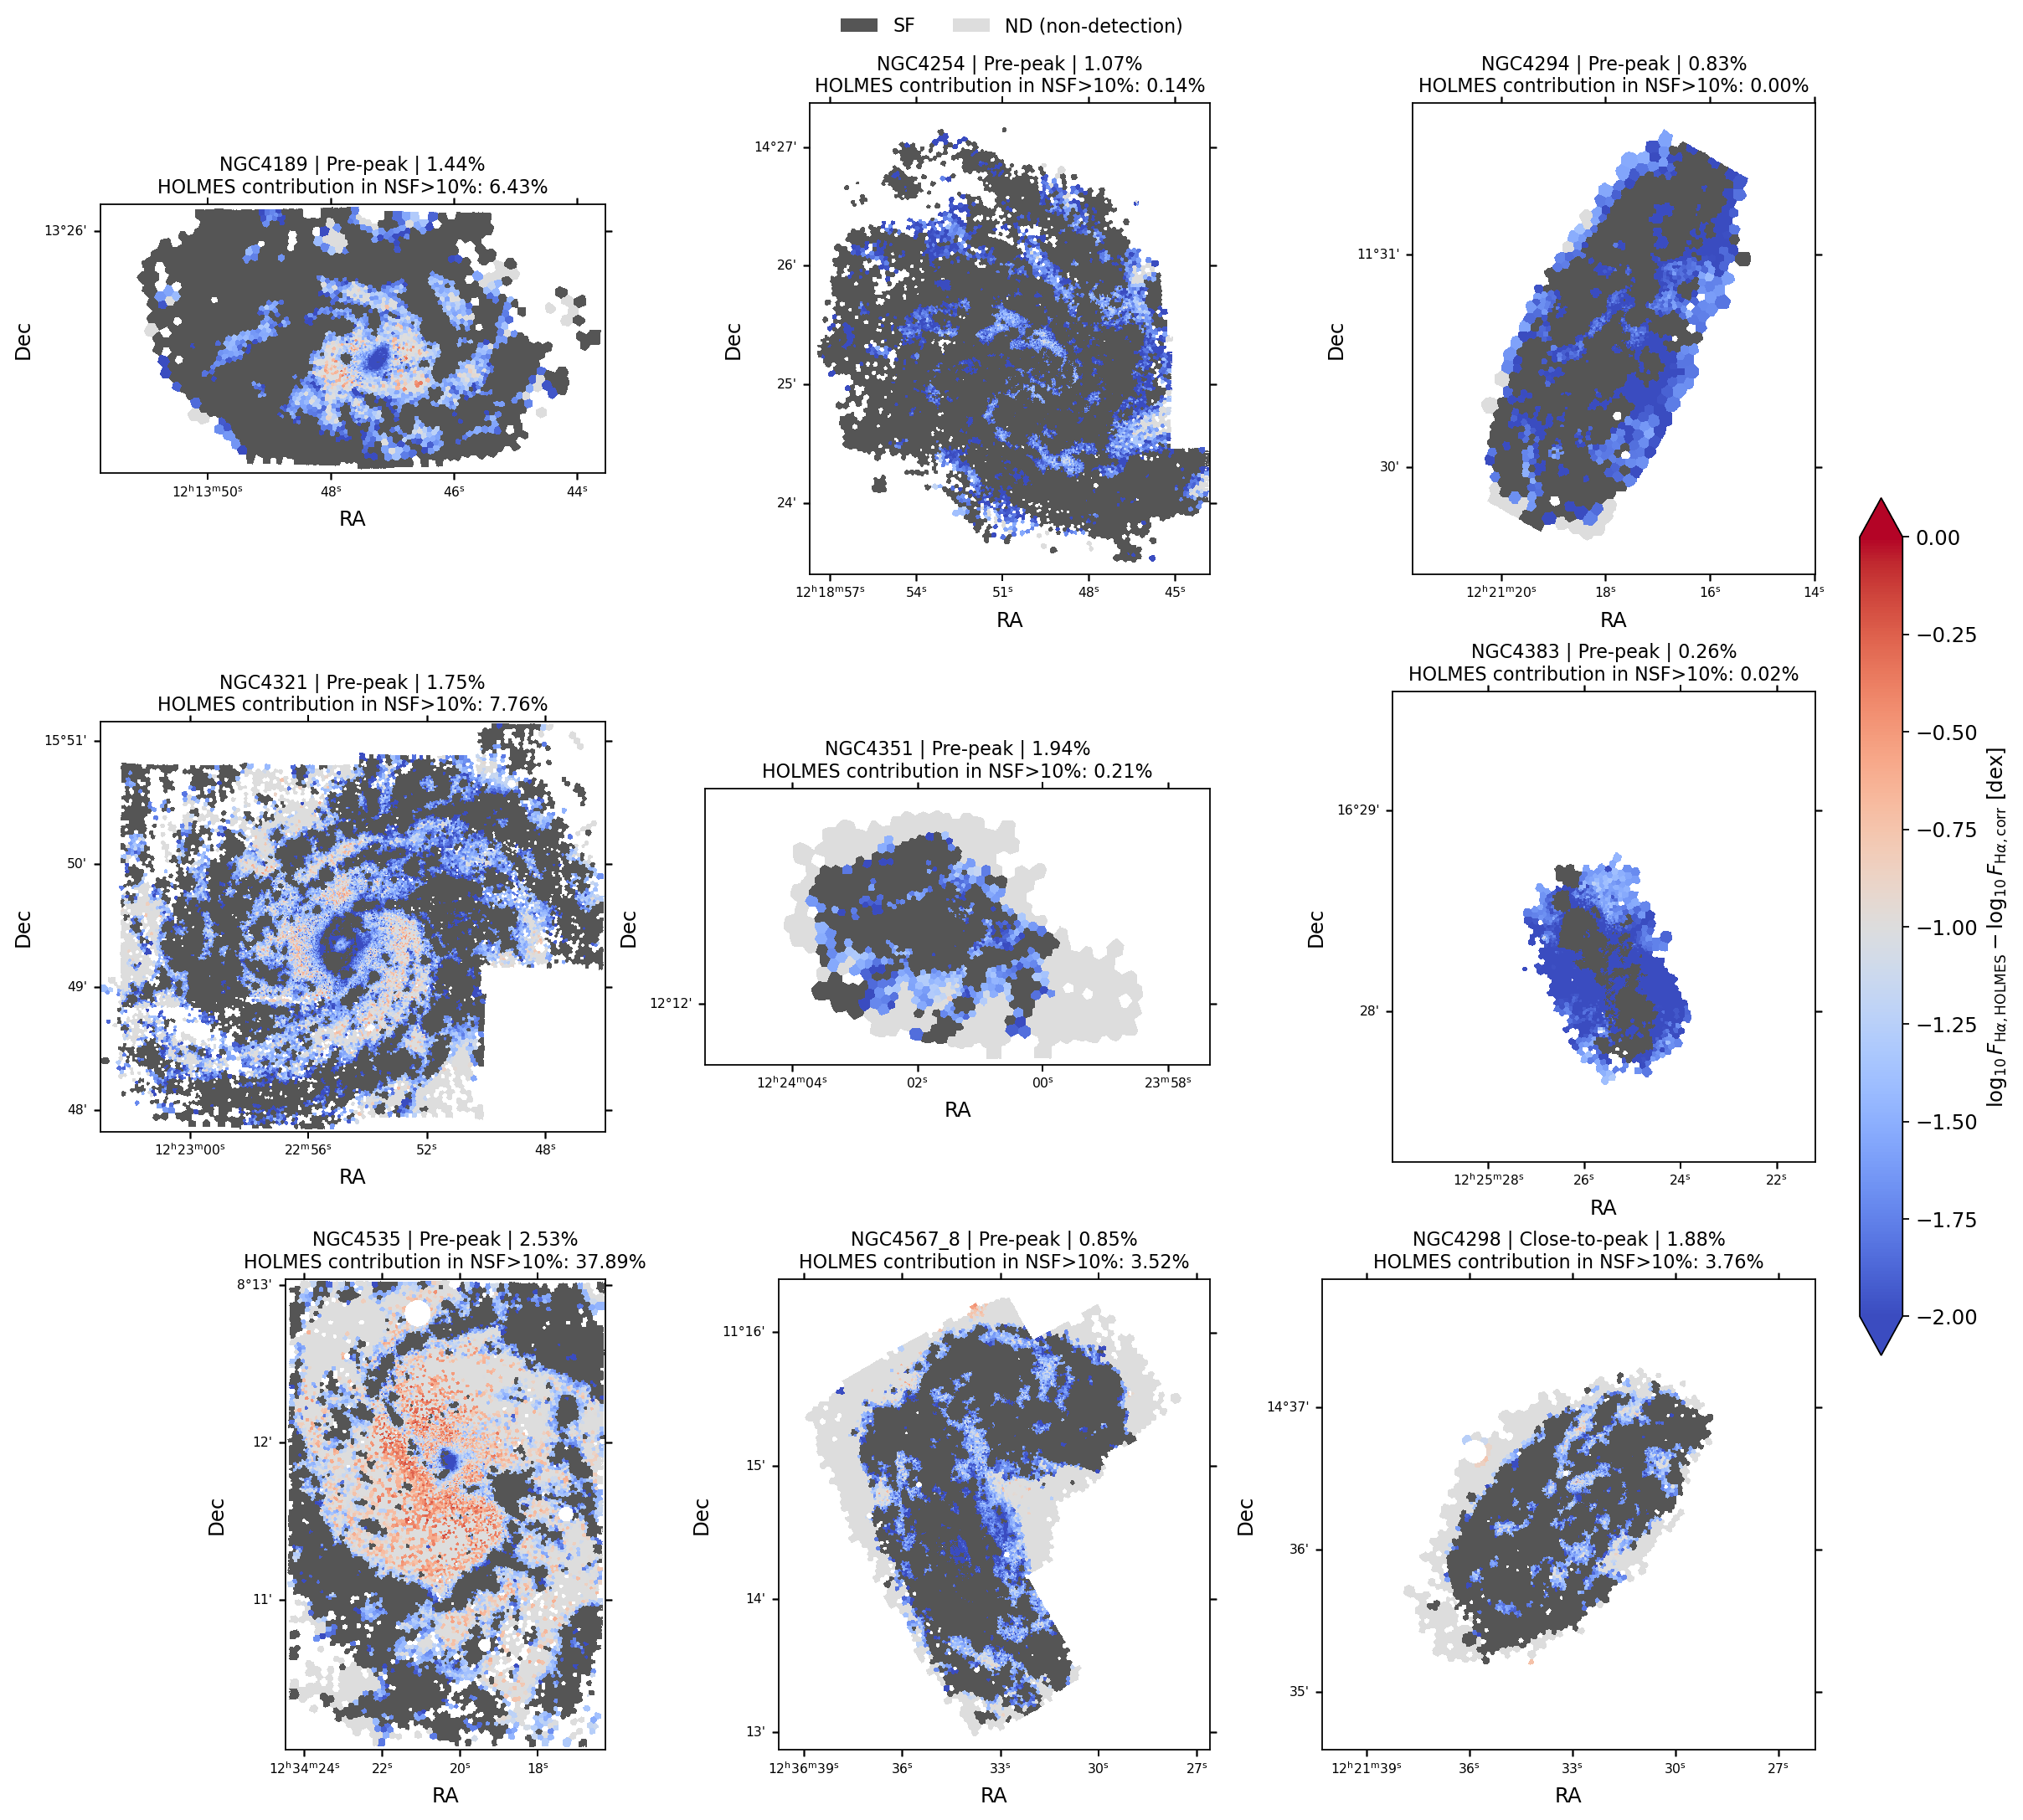

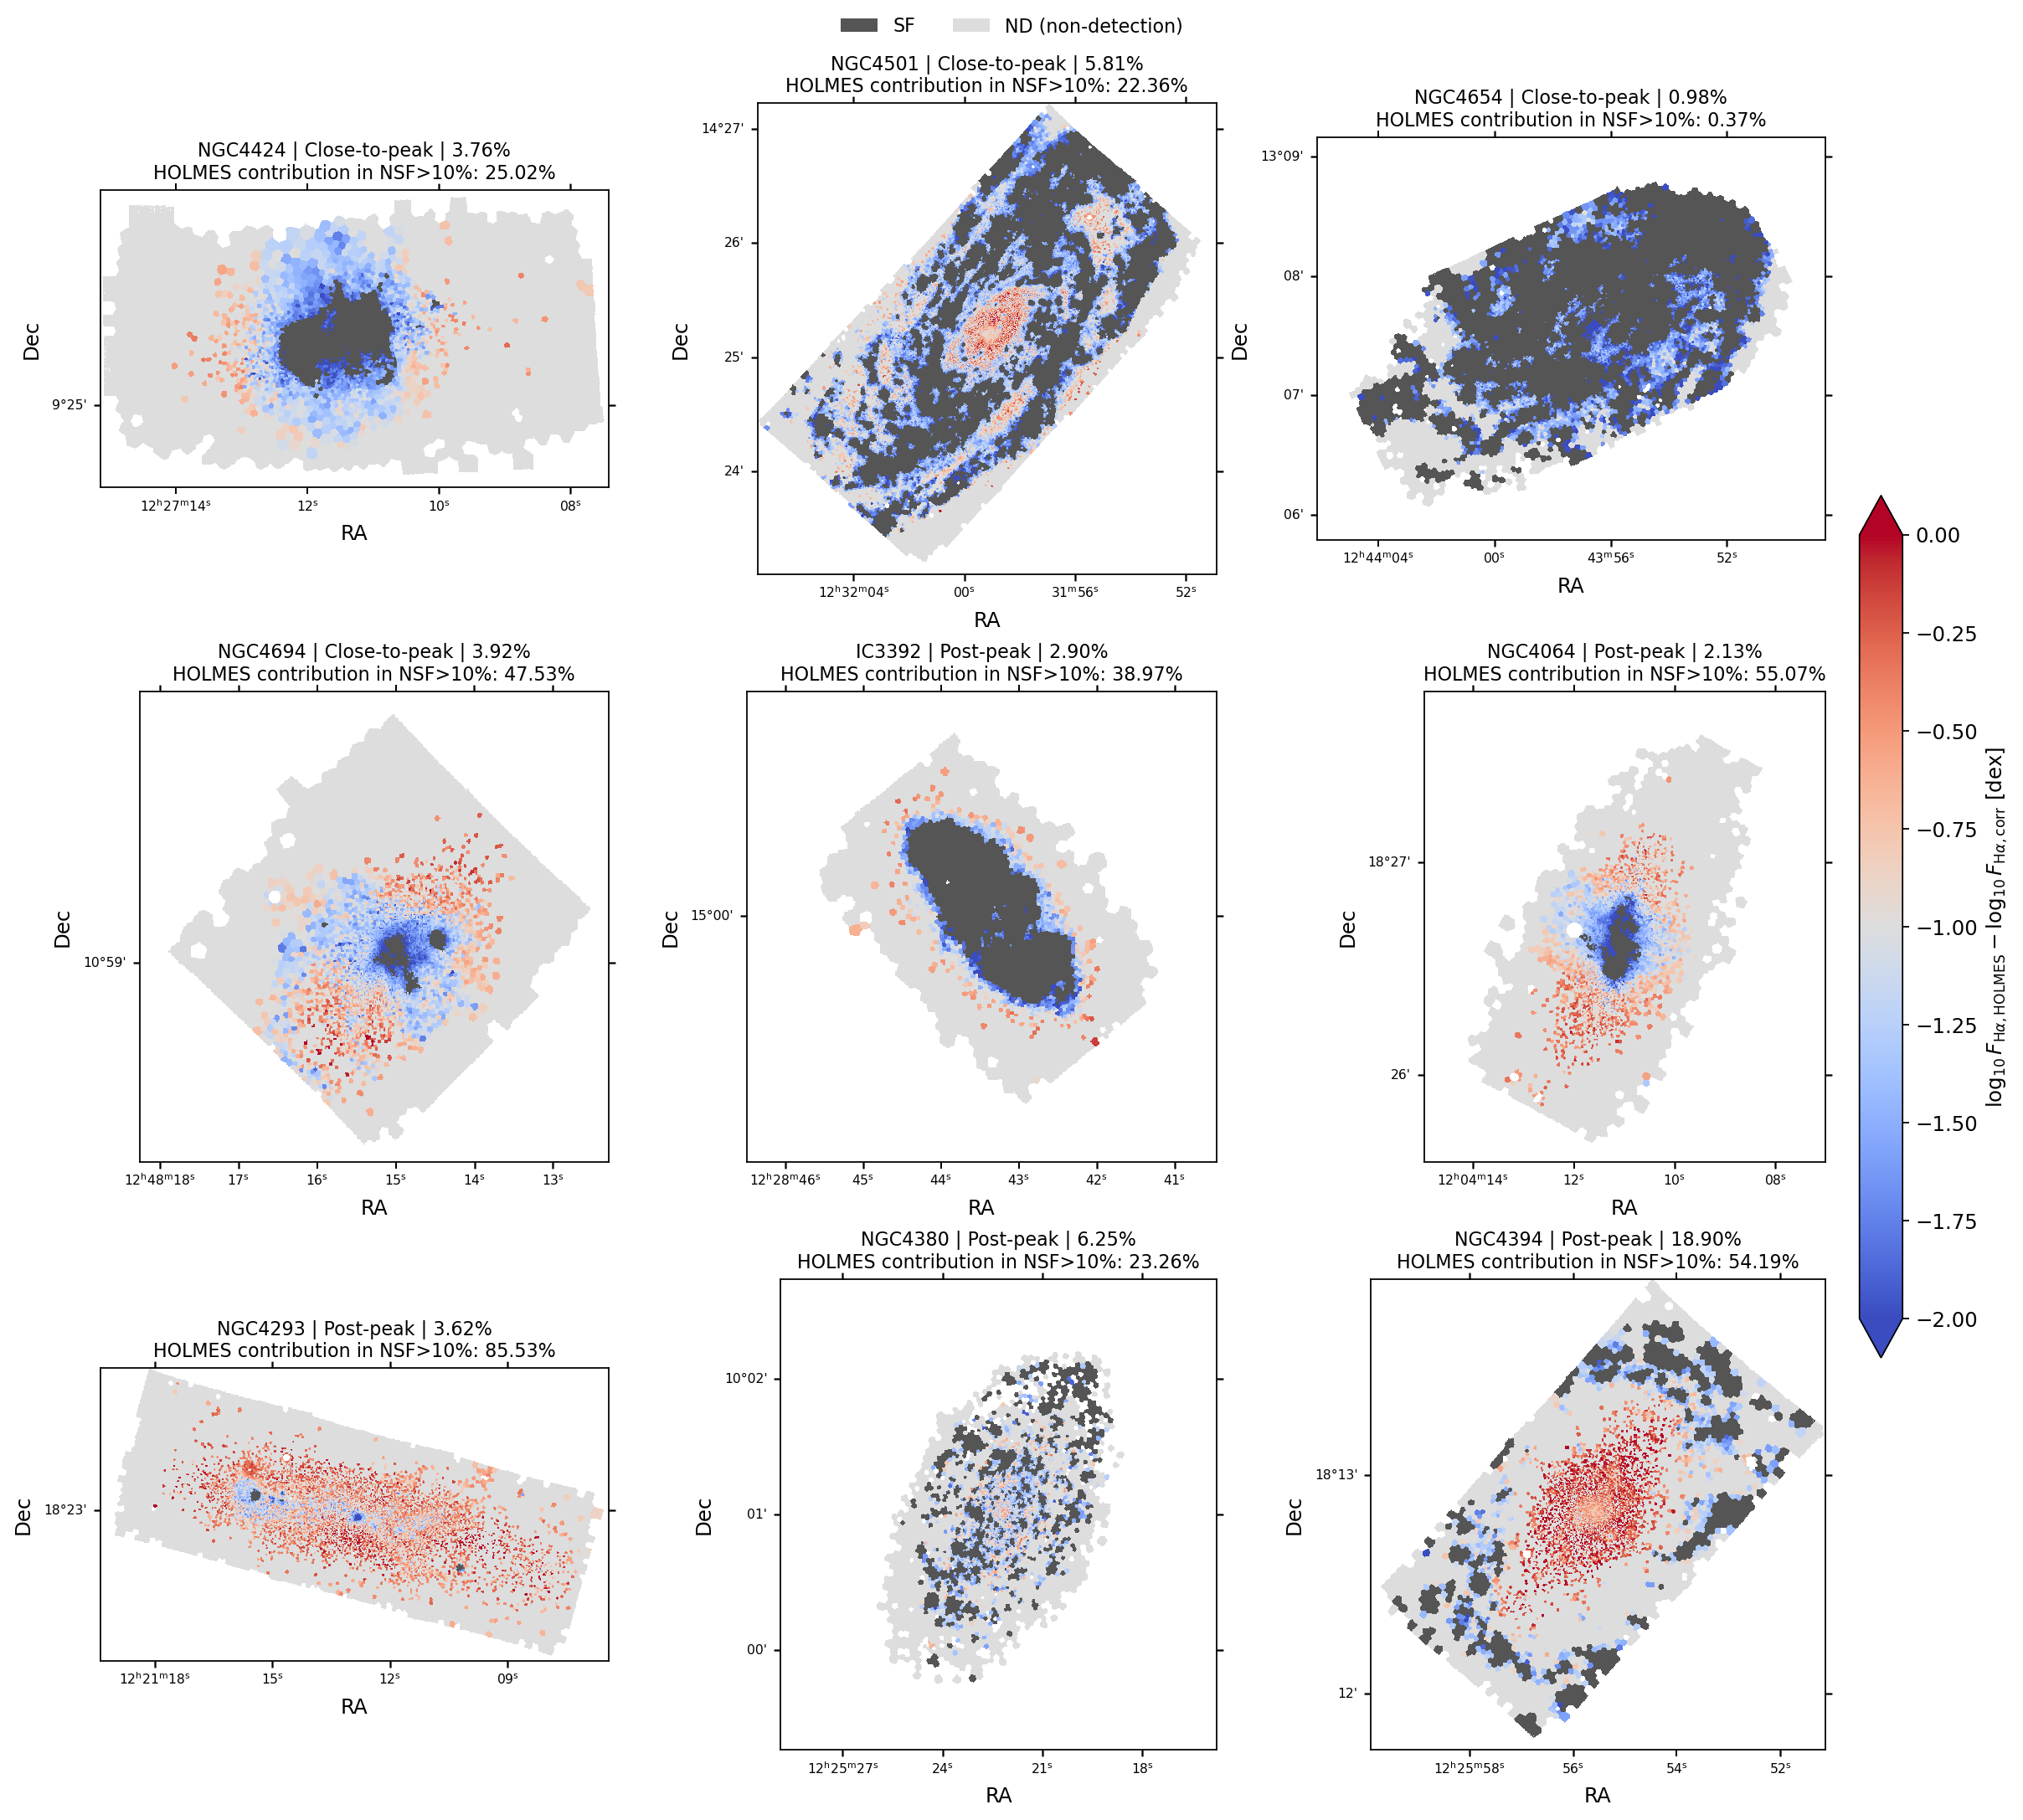

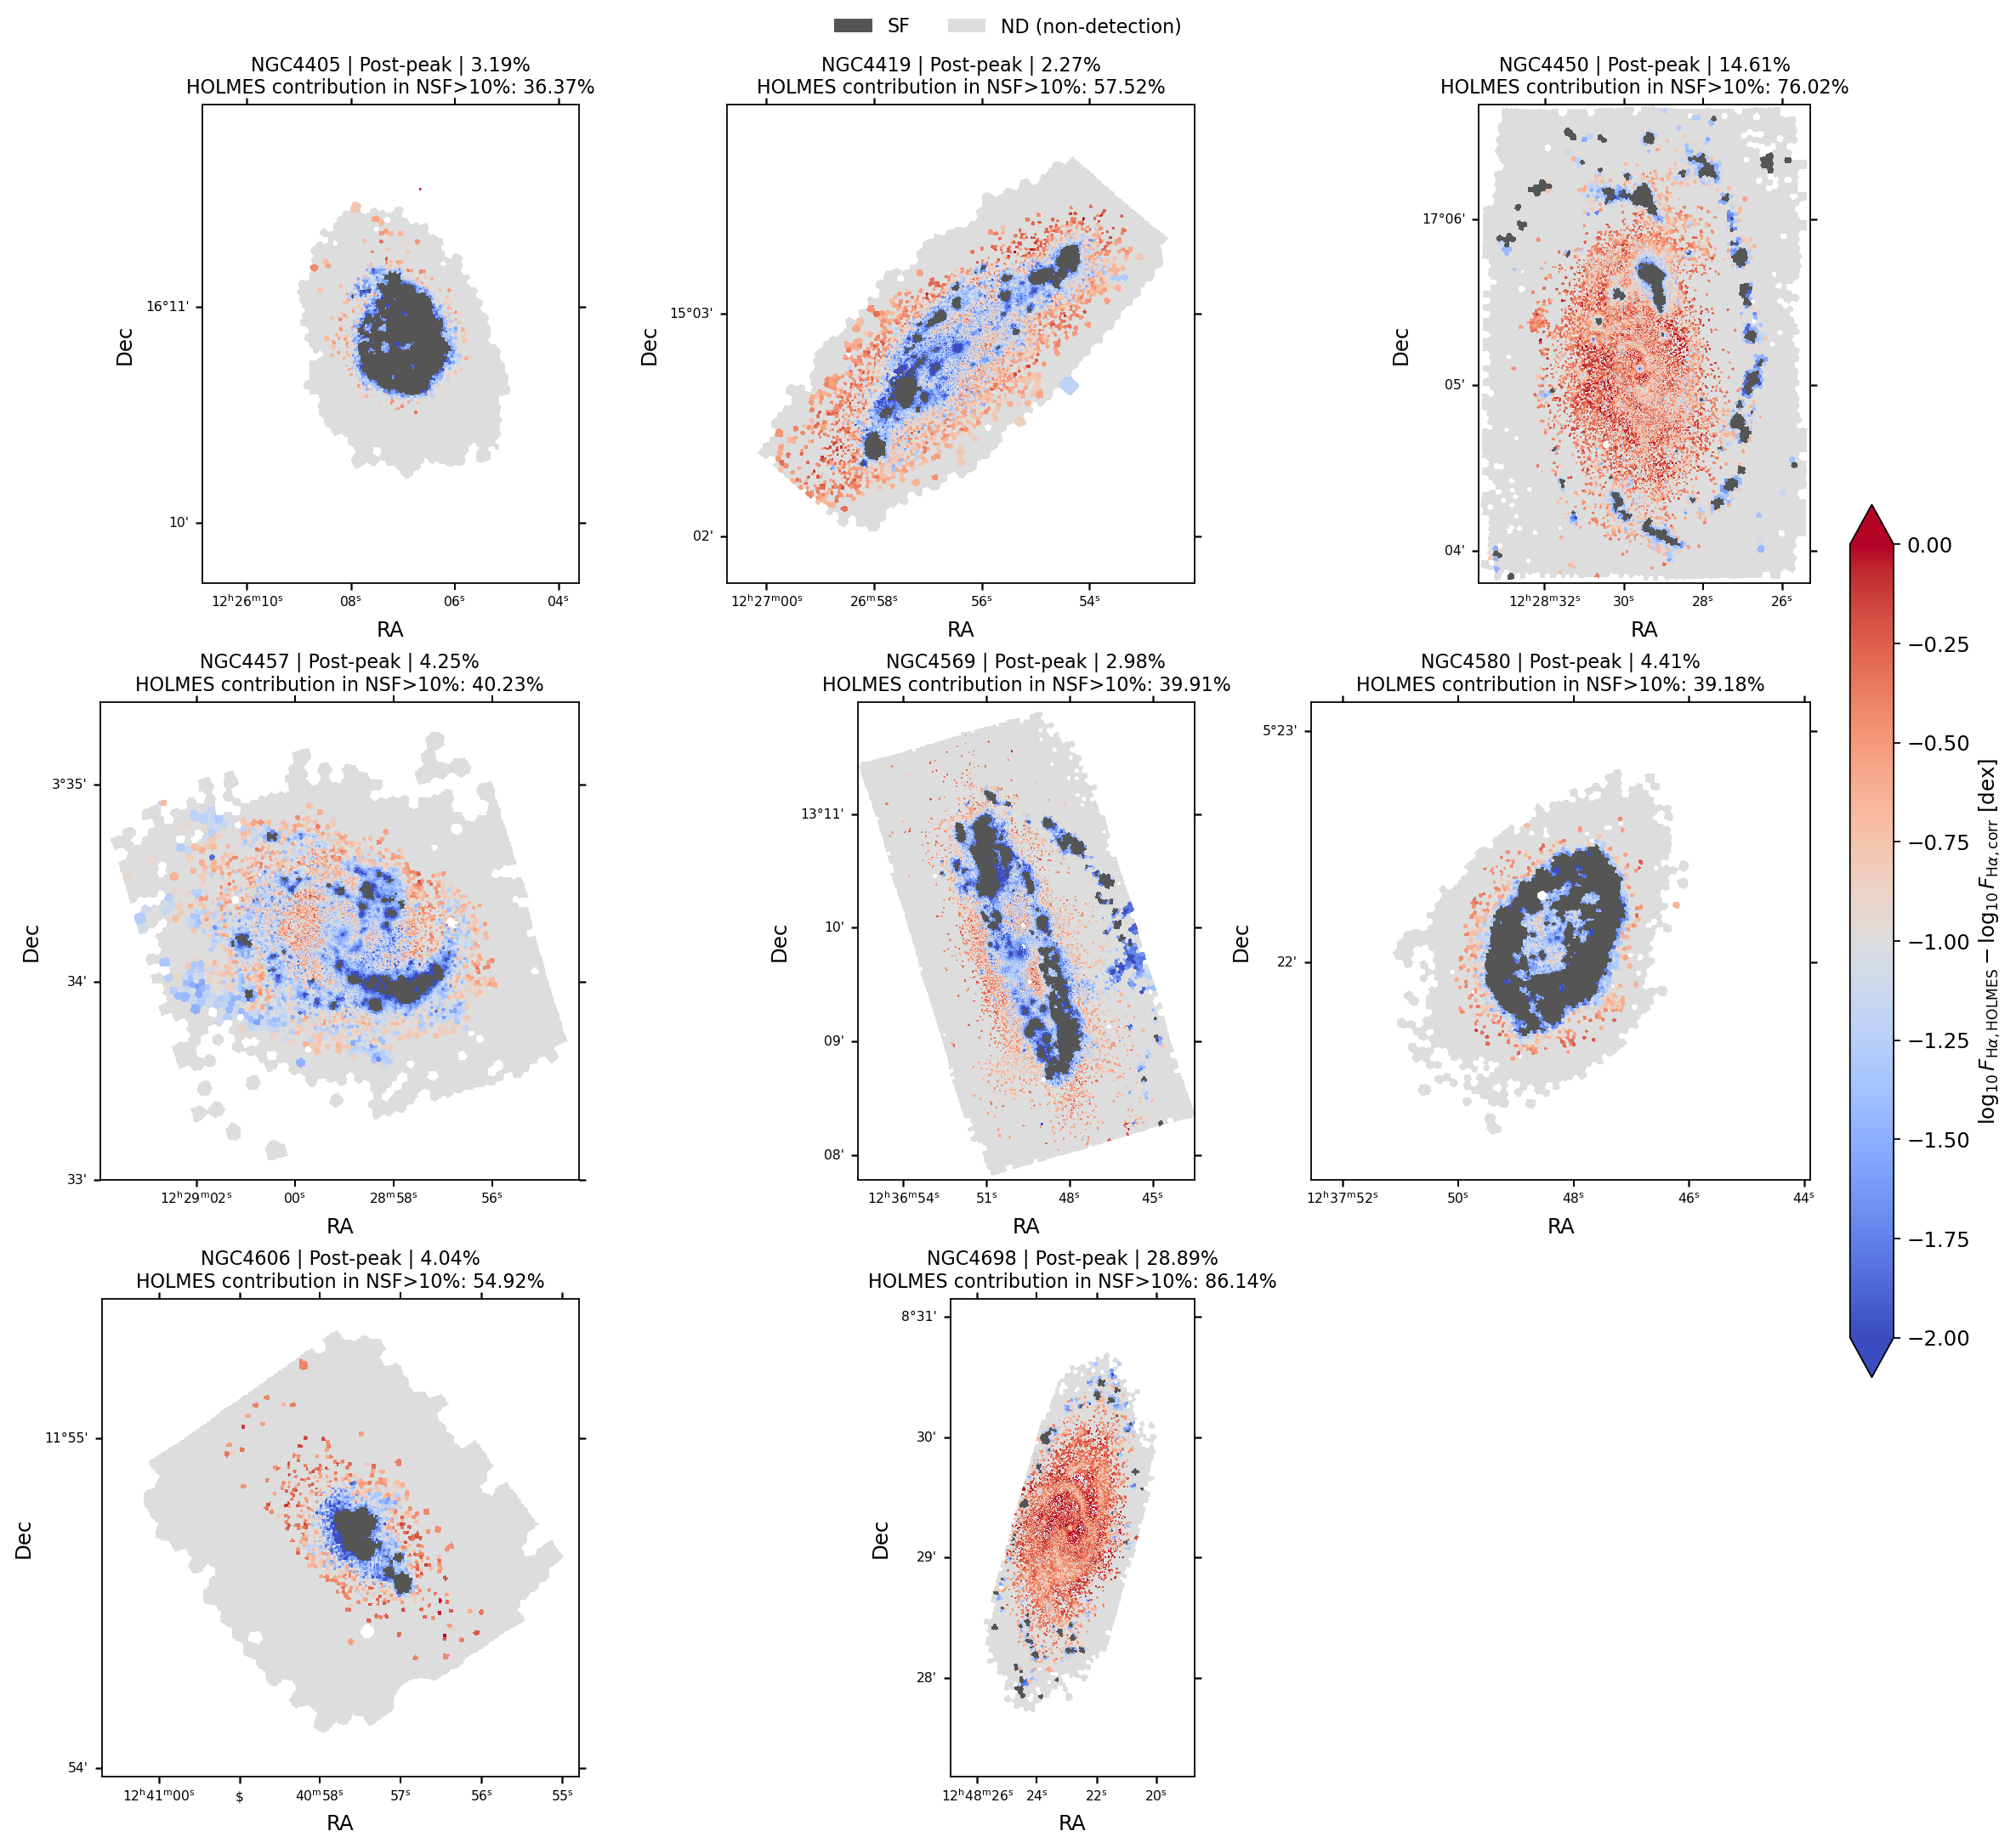

<Figure size 1800x1620 with 10 Axes>

<Figure size 1800x1620 with 10 Axes>

<Figure size 1800x1620 with 9 Axes>

In [16]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

map_order = sorted(spatial_maps, key=lambda m: (STAGE_ORDER.index(m['stage']), m['GALID']))
for page, start in enumerate(range(0, len(map_order), MAPS_PER_PAGE), 1):
    group = map_order[start:start+MAPS_PER_PAGE]
    ncol = 3
    nrow = math.ceil(len(group)/ncol)
    fig = plt.figure(figsize=(15, 4.5*nrow), constrained_layout=True)
    axes = []
    for j, record in enumerate(group):
        ax = fig.add_subplot(nrow, ncol, j+1, projection=WCS(record['header']).celestial)
        axes.append(ax)
        assert not np.any(record['sf'] & record['nd'])
        assert not np.any(record['nsf'] & (record['sf'] | record['nd']))
        background = np.full(record['delta'].shape, np.nan)
        background[record['nd']] = 0.
        background[record['sf']] = 1.
        ax.imshow(background, origin='lower', cmap=ListedColormap(['#dddddd', '#555555']),
                  vmin=0, vmax=1, interpolation='nearest')
        im = ax.imshow(record['delta'], origin='lower', cmap='coolwarm',
             vmin=-2.0, vmax=0.0,
             interpolation='nearest')
        budget = GALAXY_BUDGET.loc[GALAXY_BUDGET.GALID.eq(record['GALID'])].iloc[0]
        ax.set_title(f"{record['GALID']} | {STAGE_LABELS[record['stage']]} | "
                     f"{100*budget.integrated_HOLMES_fraction:.2f}%\n"
                     f"HOLMES contribution in NSF>10%: {100*budget.fraction_gt_0p1:.2f}%", fontsize=10)
        ax.set_xlabel('RA')
        ax.set_ylabel('Dec')
        ax.coords[0].set_major_formatter('hh:mm:ss')
        ax.coords[1].set_major_formatter('dd:mm')
        ax.coords[0].set_ticklabel(size=7)
        ax.coords[1].set_ticklabel(size=7)
    fig.legend(handles=[Patch(facecolor='#555555', label='SF'),
                        Patch(facecolor='#dddddd', label='ND (non-detection)')],
               loc='outside upper center', ncol=2, frameon=False, fontsize=10)
    cb = fig.colorbar(im, ax=axes, fraction=.025, pad=.02, extend='both')
    cb.set_label(r'$\log_{10}F_{\mathrm{H}\alpha,\mathrm{HOLMES}}-\log_{10}F_{\mathrm{H}\alpha,\mathrm{corr}}$ [dex]')
    finish_figure(fig, f'06_NSF_HOLMES_spatial_maps_page_{page:02d}')

## Numerical accounting and reproducible outputs
The assertions verify support accounting, selection cuts and the single mass-based prediction. Summary CSV tables preserve counts and denominators. Set SAVE_SPAXEL_TABLE=True for an optional large compressed export of every measured pixel. Model/systematic uncertainties are not captured by these numerical checks. The provenance JSON records source and Equation 33 note hashes, constants, software versions and the approximate mass-fraction method. Re-running updates only this notebook's dated asset directory.

In [17]:
assert MEASUREMENT_QC.N_positive_flux.sum() == len(PIXELS)
assert np.all(MEASUREMENT_QC.N_HOLMES_pair <= MEASUREMENT_QC.N_positive_flux)
assert np.all(MEASUREMENT_QC.N_log_HOLMES_pair + MEASUREMENT_QC.N_zero_prediction
              == MEASUREMENT_QC.N_HOLMES_pair)
finite = np.isfinite(PIXELS.ratio_HOLMES)
assert sample.inclination.lt(I_MAX_PRIMARY).all()
assert PIXELS.inclination_deg.lt(I_MAX_PRIMARY).all()
assert PIXELS.snr_postfit.gt(SFH_SNR_POSTFIT_MIN).all()
expected_flux = (HOLMES_ABSORBED_FRACTION * EPSILON_ALPHA * Q_HOLMES
                 * 10.**PIXELS.logMstar.to_numpy()
                 / (4*np.pi*(PIXELS.GALID.map(PRODUCT_PROVENANCE.set_index('GALID').DIST_MPC)
                              .to_numpy()*MPC_CM)**2))
np.testing.assert_allclose(PIXELS.F_Ha_HOLMES, expected_flux, rtol=1e-12)
assert int(all_budget.N_gt_1) == int((PIXELS.ratio_HOLMES > 1).sum())
assert sum(m['n_above'] for m in spatial_maps) == int(all_budget.N_gt_1)
assert int(all_budget.N_HOLMES) == int(finite.sum())
assert np.allclose(PIXELS.loc[PIXELS.F_Ha_HOLMES > 0, 'delta_logflux'],
                   np.log10(PIXELS.loc[PIXELS.F_Ha_HOLMES > 0, 'ratio_HOLMES']))
if SAVE_OUTPUTS:
    tables = dict(sample_QC=SAMPLE_QC, measurement_QC=MEASUREMENT_QC,
                  product_provenance=PRODUCT_PROVENANCE, galaxy_budget=GALAXY_BUDGET,
                  stage_budget=STAGE_BUDGET, equal_galaxy_budget=EQUAL_GALAXY_BUDGET.reset_index())
    for name, table in tables.items():
        table.to_csv(ASSET_DIR / (name+'.csv'), index=False)
    if SAVE_SPAXEL_TABLE:
        PIXELS.to_csv(ASSET_DIR / 'NSF_spaxel_measurements.csv.gz', index=False,
                      compression=dict(method='gzip', mtime=0))
    import scipy, astropy, sys
    note_path = PROJECT_ROOT.parent / 'MAUVE' / '20261003 The Origin of Fading Emission Lines and Increasing BPT Line Ratios along Infall Stages.md'
    metadata = dict(date='2026-10-20',
        parent_notebook='20261019_check_NSF_Halpha_corrected_flux_HOLMES_by_stage.ipynb',
        parent_notebook_sha256='df517edaa776667ee027e418d5509824c4d867a7cd2b24474da0b9d657ed3568',
        local_mass_bin_edges=[str(x) for x in LOCAL_MASS_BIN_EDGES],
        radius_bin_edges=[str(x) for x in RADIAL_BIN_EDGES], source_notebook='20261017_check_NSF_SII_ratio_EW_SF_proximity_sigma_by_stage.ipynb',
        source_sha256=SOURCE_SHA256, equation_note_sha256=hashlib.sha256(note_path.read_bytes()).hexdigest(),
        Q_HOLMES=Q_HOLMES, EPSILON_ALPHA=EPSILON_ALPHA,
        HOLMES_ABSORBED_FRACTION=HOLMES_ABSORBED_FRACTION, MASS_DISTANCE_MPC=MASS_DISTANCE_MPC,
        mass_assumption='Sigma_old approximately Sigma_star; no population-weight correction',
        inclination_max_exclusive=I_MAX_PRIMARY, SNR_POSTFIT_min_exclusive=SFH_SNR_POSTFIT_MIN,
        SF_reference_EW_min=SF_REFERENCE_EW_HA_MIN, N_products=len(sample), N_NSF_flux=len(PIXELS),
        python=sys.version, numpy=np.__version__, pandas=pd.__version__,
        matplotlib=mpl.__version__, scipy=scipy.__version__, astropy=astropy.__version__)
    (ASSET_DIR / 'analysis_provenance.json').write_text(json.dumps(metadata, indent=2)+'\n')
print('PASS: strict inclination/SNR selection, single Eq33 prediction, finite-pair, threshold and map accounting')
print(f'Output directory: {ASSET_DIR}')

PASS: strict inclination/SNR selection, single Eq33 prediction, finite-pair, threshold and map accounting
Output directory: /Users/Igniz/Desktop/ICRAR/further/20261020_NSF_Halpha_HOLMES_assets


## Reading these results

- A trend of flux with EW is partly mathematically coupled because EW contains Halpha; it is not independent evidence for an ionizing source. Dust corrections also differ between gas and continuum.
- The nearest high-EW SF distance is an association proxy. A trend can reflect surface brightness, masks, radius or gas conditions; a missing local SF reference does not establish the absence of leaked OB photons.
- Equation 33 is an available photon budget under an assumed q, the assumption Sigma_old approximately Sigma_star and full local absorption. Ratios above one can also flag excess assumed mass/q, absorption losses or a mismatch in aperture/transport. They are not measured HOLMES fractions.
- The strict >1 count is not an uncertainty-aware classification. Correlated errors in stellar mass, EW, Balmer-decrement flux, PSF, and population models are not propagated here. No physical fraction is obtained by clipping the ratio.
- Compare per-galaxy and pooled summaries together. Stage differences may reflect unequal sample size, stellar mass, radius and selection. This notebook does not fit a stripping clock or a causal infall model.